# Week 5 — 5-fold 결과·사례·PR·속도 통합 분석

기존 YOLOv8 / CropCNN 가중치와 **복구 완료된 outer 예측**을 사용합니다. 재학습과 outer 데이터 기반 alpha/임계값 튜닝은 하지 않습니다. **Colab GPU 런타임**에서 위에서 아래로 실행하세요.

- 표·그래프: fold별 결과, 평균±표본 표준편차, paired 차이, COCO PR@IoU 0.5.
- 사례: **오탐 제거 / 정답 누락 / 누락 복구 / 새 오탐 / 공통 실패**, 유형별 최대 3장. GT·YOLO·YOLO+CNN 나란히 표시.
- 이유: 점수·임계값·IoU·GT 크기로 확인한 사실을 이미지에 기록. 그림자/흐림/균열 등 의미적 원인은 사람이 검토해 메모를 추가합니다. 자동 설명은 인과관계 증명이 아닙니다.
- 속도: 모든 5 folds에 대해 기존 해상도 FP32 / 640 FP32 / 640 FP16. 기본 30장×3회, 모델별 워밍업 10회. 해상도·정밀도별 outer 정확도도 재측정합니다.
- 결과는 기존 평가 폴더 아래 **새 `week5_report_...` 폴더**에 저장. 최종 HTML과 ZIP 생성.

이 노트북은 첨부된 초기 학습 코드가 아니라 이후 생성된 `kfold5` 및 `evaluation_repaired_*` 출력 구조에 맞춰 작성됐습니다. Colab `/content`의 예전 `.py` 파일은 필요하지 않습니다.


## 1. Drive 연결과 경로·출력 설정

In [1]:
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')

DATA_ROOT = Path('/content/drive/MyDrive/Pothole')
RUN_ROOT = DATA_ROOT / 'week5_kfold_results/kfold5'
EVAL_DIR = RUN_ROOT / 'evaluation_repaired_20261008_125921_547498'
# 경로가 바뀌었다면 위 두 줄만 실제 경로로 수정하세요.

CASES_PER_TYPE = 3  # 유형당 최대 3장: 총 최대 15장
SEED = 20261008
BENCH_IMAGES_PER_FOLD = 30
BENCH_REPEATS = 3
BENCH_WARMUP = 10
FULL_SCENARIO_ACCURACY = True
ALLOW_VERSION_DRIFT = False  # 복구 실행과 버전이 다르면 명시적으로 멈춤
MANUAL_NOTES = {}  # 예: {'125': '사람 검토: 도로 그림자와 겹쳐 보임. 원인 추정이며 확정 아님.'}

required=[RUN_ROOT/'source_manifest.json', RUN_ROOT/'fold_indices.json', EVAL_DIR/'oof_predictions.json', EVAL_DIR/'cv_fold_results.csv']
missing=[str(p) for p in required if not p.is_file()]
if missing:
    print('현재 보이는 완료 평가 폴더:', [str(p.parent) for p in RUN_ROOT.glob('evaluation_repaired_*/oof_predictions.json')])
    raise FileNotFoundError('필요한 파일이 없습니다. 경로를 수정하세요:\n'+'\n'.join(missing))
print('사용할 복구 결과:', EVAL_DIR)


Mounted at /content/drive
사용할 복구 결과: /content/drive/MyDrive/Pothole/week5_kfold_results/kfold5/evaluation_repaired_20261008_125921_547498


## 2. 필요한 패키지 확인
설치된 모델 패키지는 자동 업그레이드하지 않습니다. 없는 패키지만 설치하고, torch/torchvision/ultralytics는 복구 실행의 버전을 참고합니다. GPU 추론은 복구 때와 같은 환경이 가장 적합합니다.

In [2]:
import sys, subprocess, importlib.util, json
expected=json.loads((EVAL_DIR/'fold1/environment_comparison.json').read_text())['actual']
packages={'numpy':'numpy','pandas':'pandas','matplotlib':'matplotlib','PIL':'Pillow','cv2':'opencv-python','pycocotools':'pycocotools', 'torch':'torch','torchvision':'torchvision','ultralytics':'ultralytics'}
for module,package in packages.items():
    if importlib.util.find_spec(module) is None:
        spec=f'{package}=={expected[package]}' if package in expected else package
        subprocess.check_call([sys.executable,'-m','pip','install','-q',spec])
print('복구 환경:', expected)


복구 환경: {'ultralytics': '8.4.174', 'torch': '2.11.0+cu130', 'torchvision': '0.26.0+cu130'}


## 3. 분석 모듈 준비
이 셀에 분석 코드·COCO 수정 평가기·CropCNN 정의와 한글 폰트가 포함되어 있습니다. 기존 `/content/week5_*.py`에 의존하지 않습니다. 내부 파일은 전용 폴더에 설치합니다.

In [3]:
#@title 분석 모듈과 한글 폰트 준비 (실행)
import base64,zlib,sys,importlib,hashlib
BUNDLE=Path('/content/week5_report_bundle')
BUNDLE.mkdir(exist_ok=True)
MODULES={'week5_report.py': '"""Week 5: frozen outer-fold reporting; never train or tune on outer data."""\nfrom pathlib import Path\nimport json, time, hashlib, textwrap, platform, importlib.metadata\nimport numpy as np\nimport pandas as pd\nimport matplotlib\nmatplotlib.use(\'Agg\')\nimport matplotlib.pyplot as plt\nfrom matplotlib.patches import Rectangle\nfrom PIL import Image\nfrom week5_coco_fixed import evaluate\n\nMODELS=[\'YOLOv8\',\'YOLOv8+CNN\']\nMETRICS=[\'map\',\'map_50\',\'precision\',\'recall\',\'f1\',\'fp_per_image\']\nLABELS=[\'mAP50-95\',\'mAP50\',\'Precision\',\'Recall\',\'F1\',\'FP/image\']\nCASES={\'fp_removed\':\'오탐 제거 성공\',\'tp_lost\':\'정답 누락 발생\',\'tp_gained\':\'누락 포트홀 복구\',\'fp_added\':\'새 오탐 발생\',\'both_miss\':\'두 방법의 공통 실패\'}\n\ndef read(p): return json.loads(Path(p).read_text(encoding=\'utf-8\'))\ndef dump(p,x): Path(p).write_text(json.dumps(x,ensure_ascii=False,indent=2),encoding=\'utf-8\')\ndef csv(p,x): pd.DataFrame(x).to_csv(p,index=False,encoding=\'utf-8-sig\')\ndef savefig(fig,p):\n    fig.savefig(p,dpi=160,bbox_inches=\'tight\'); plt.close(fig)\ndef setup_font():\n    from matplotlib import font_manager\n    for p in [str(Path(__file__).with_name(\'NanumGothic.ttf\')), \'/usr/share/fonts/truetype/nanum/NanumGothic.ttf\',\'/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc\']:\n        if Path(p).exists():\n            font_manager.fontManager.addfont(p); plt.rcParams[\'font.family\']=font_manager.FontProperties(fname=p).get_name(); break\n    plt.rcParams[\'axes.unicode_minus\']=False\n\ndef ious(a,b):\n    a=np.asarray(a,float).reshape(-1,4); b=np.asarray(b,float).reshape(-1,4)\n    inter=np.maximum(np.minimum(a[:,None,2:],b[None,:,2:])-np.maximum(a[:,None,:2],b[None,:,:2]),0).prod(2)\n    return inter/np.maximum(np.maximum(a[:,2:]-a[:,:2],0).prod(1)[:,None]+np.maximum(b[:,2:]-b[:,:2],0).prod(1)[None,:]-inter,1e-9)\n\ndef match(boxes,scores,gt,threshold):\n    scores=np.asarray(scores); idx=np.flatnonzero(scores>=threshold)\n    idx=idx[np.argsort(-scores[idx],kind=\'stable\')]; ov=ious(boxes,gt); pairs={}; used=set(); fp=[]\n    for i in idx:\n        eligible=[j for j in range(len(gt)) if j not in used and ov[i,j]>=.5]\n        if eligible:\n            j=max(eligible,key=lambda j:ov[i,j]); pairs[int(i)]=j; used.add(j)\n        else: fp.append(int(i))\n    return {\'pairs\':pairs,\'fp\':fp,\'fn\':sorted(set(range(len(gt)))-used),\'kept\':idx.tolist()}\n\ndef counts(m): return [len(m[\'pairs\']),len(m[\'fp\']),len(m[\'fn\'])]\ndef op(c):\n    tp,fp,fn=np.asarray(c).sum(0)\n    return dict(tp=int(tp),fp=int(fp),fn=int(fn),precision=float(tp/max(tp+fp,1)),recall=float(tp/max(tp+fn,1)),f1=float(2*tp/max(2*tp+fp+fn,1)),fp_per_image=float(fp/len(c)))\n\ndef load_report(run_root,eval_dir,data_root,output=None):\n    root=Path(run_root); ed=Path(eval_dir)\n    if not root.is_dir() or not ed.is_dir(): raise FileNotFoundError(f\'RUN_ROOT={root}\\nEVAL_DIR={ed}\')\n    records=read(ed/\'oof_predictions.json\'); source=read(root/\'source_manifest.json\')\n    foldspec=read(root/\'fold_indices.json\')[\'folds\']\n    if len(foldspec)!=5 or {x[\'fold\'] for x in records}!={1,2,3,4,5}: raise ValueError(\'5 folds required\')\n    ids=[r[\'source_index\'] for r in records]\n    if len(ids)!=len(set(ids)) or set(ids)!=set(range(len(source))): raise ValueError(\'OOF coverage mismatch\')\n    settings={}; configs={}; runs={}\n    for fs in foldspec:\n        k=fs[\'fold\']\n        if {r[\'source_index\'] for r in records if r[\'fold\']==k}!=set(fs[\'test\']): raise ValueError(f\'fold{k}: membership mismatch\')\n        settings[k]=read(ed/f\'fold{k}/locked_validation_settings.json\')\n        options=[p for p in (root/f\'fold{k}\').glob(\'week5_*\') if (p/\'test_predictions.json\').is_file()]\n        if len(options)!=1: raise ValueError(f\'fold{k}: expected one original run, found {options}\')\n        runs[k]=options[0]; configs[k]=read(options[0]/\'config.json\')\n    for r in records:\n        k=r[\'fold\']; s=settings[k]; r[\'image\']=str(Path(data_root)/source[r[\'source_index\']][\'relative_path\'])\n        for field in [\'gt\',\'boxes\']: r[field]=np.array(r[field],np.float32).reshape(-1,4)\n        for field in [\'yolo_scores\',\'cnn_probs\',\'hybrid_scores\']: r[field]=np.array(r[field],np.float32)\n        if any(len(r[f])!=len(r[\'boxes\']) for f in [\'yolo_scores\',\'cnn_probs\',\'hybrid_scores\']): raise ValueError(\'Misaligned predictions\')\n        if not np.isfinite(r[\'cnn_probs\']).all() or np.any((r[\'cnn_probs\']<0)|(r[\'cnn_probs\']>1)): raise ValueError(\'Invalid CNN probability\')\n        expected=r[\'yolo_scores\']*np.maximum(r[\'cnn_probs\'],1e-8)**s[\'alpha\']\n        if not np.allclose(expected,r[\'hybrid_scores\'],rtol=1e-5,atol=1e-7): raise ValueError(\'Saved alpha/scores mismatch\')\n    out=Path(output) if output else ed/(\'week5_report_\'+time.strftime(\'%Y%m%d_%H%M%S\'))\n    out.mkdir(parents=True,exist_ok=False)\n    for d in [\'graphs\',\'cases\',\'speed\']: (out/d).mkdir()\n    dump(out/\'protocol.json\',{\'run_root\':str(root),\'evaluation\':str(ed),\'operating_iou\':.5,\'training\':False,\'outer_tuning\':False,\'case_reason\':\'score/IoU/threshold evidence; visual causes require human review\'})\n    return dict(root=root,ed=ed,out=out,records=records,source=source,settings=settings,configs=configs,runs=runs)\n\ndef make_tables_graphs(ctx):\n    setup_font(); out=ctx[\'out\']; rows=[]; prs=[]; image_rows=[]\n    for k in range(1,6):\n        rr=[r for r in ctx[\'records\'] if r[\'fold\']==k]; s=ctx[\'settings\'][k]\n        for model,field,th in [(MODELS[0],\'yolo_scores\',s[\'yolo_threshold\']),(MODELS[1],\'hybrid_scores\',s[\'hybrid_threshold\'])]:\n            pred=[dict(boxes=r[\'boxes\'],scores=r[field]) for r in rr]\n            metrics,ev=evaluate(pred,rr,int(ctx[\'configs\'][k][\'max_det\']))\n            cc=[counts(match(r[\'boxes\'],r[field],r[\'gt\'],th)) for r in rr]\n            rows.append(dict(fold=k,model=model,threshold=th,alpha=0 if model==MODELS[0] else s[\'alpha\'],**metrics,**op(cc)))\n            for r,c in zip(rr,cc): image_rows.append(dict(fold=k,source_index=r[\'source_index\'],model=model,tp=c[0],fp=c[1],fn=c[2]))\n            precision=ev.eval[\'precision\'][0,:,0,0,-1]\n            for recall,p in zip(ev.params.recThrs,precision):\n                prs.append(dict(fold=k,model=model,recall=float(recall),precision=float(p)))\n        print(f\'표/COCO PR 검증 완료: Fold {k}/5\',flush=True)\n    df=pd.DataFrame(rows); old=pd.read_csv(ctx[\'ed\']/\'cv_fold_results.csv\')\n    joined=df.merge(old,on=[\'fold\',\'model\'],suffixes=(\'_new\',\'_saved\'),validate=\'one_to_one\')\n    if len(joined)!=10: raise ValueError(\'Saved result must contain both models for all 5 folds\')\n    for m in METRICS+[\'tp\',\'fp\',\'fn\']:\n        if not np.allclose(joined[m+\'_new\'],joined[m+\'_saved\'],atol=2e-6): raise ValueError(f\'Recomputed {m} differs from recovery result\')\n    csv(out/\'fold_results.csv\',rows); csv(out/\'per_image_counts.csv\',image_rows); csv(out/\'pr_curves.csv\',prs)\n    summary=df.groupby(\'model\')[METRICS].agg([\'mean\',\'std\']).reindex(MODELS)\n    summary.to_csv(out/\'mean_std.csv\',encoding=\'utf-8-sig\')\n    delta=df.pivot(index=\'fold\',columns=\'model\',values=METRICS)\n    pd.DataFrame({m:delta[m][MODELS[1]]-delta[m][MODELS[0]] for m in METRICS}).to_csv(out/\'paired_deltas.csv\',encoding=\'utf-8-sig\')\n    fig,axes=plt.subplots(2,3,figsize=(14,8))\n    for ax,m,label in zip(axes.flat,METRICS,LABELS):\n        for name in MODELS:\n            z=df[df.model==name]; ax.plot(z.fold,z[m],\'-o\',label=name)\n        ax.set(title=label,xlabel=\'Outer fold\',xticks=range(1,6)); ax.grid(alpha=.25)\n    axes.flat[0].legend(); fig.tight_layout(); savefig(fig,out/\'graphs/fold_metrics.png\')\n    fig,axes=plt.subplots(2,3,figsize=(14,8))\n    for ax,m,label in zip(axes.flat,METRICS,LABELS):\n        ax.bar(MODELS,summary[(m,\'mean\')],yerr=summary[(m,\'std\')],capsize=5,color=[\'#377eb8\',\'#ff7f00\']); ax.set_title(label); ax.set_ylim(bottom=0)\n    fig.suptitle(\'5-fold mean ± sample SD (not a confidence interval)\'); fig.tight_layout(); savefig(fig,out/\'graphs/mean_std.png\')\n    pr=pd.DataFrame(prs); fig,axes=plt.subplots(2,3,figsize=(14,8))\n    for k,ax in enumerate(axes.flat[:5],1):\n        for name in MODELS:\n            z=pr[(pr.fold==k)&(pr.model==name)]; ax.plot(z.recall,z.precision,label=name)\n            row=df[(df.fold==k)&(df.model==name)].iloc[0]; ax.scatter(row.recall,row.precision,s=28,color=ax.lines[-1].get_color())\n        ax.set(title=f\'Fold {k}: COCO interpolated PR@0.5\',xlabel=\'Recall\',ylabel=\'Precision\',xlim=(0,1),ylim=(0,1.02)); ax.grid(alpha=.2)\n    ax=axes.flat[5]\n    for name in MODELS:\n        z=pr[pr.model==name].groupby(\'recall\').precision.agg([\'mean\',\'std\']); ax.plot(z.index,z[\'mean\'],label=name); ax.fill_between(z.index,(z[\'mean\']-z[\'std\']).clip(0,1),(z[\'mean\']+z[\'std\']).clip(0,1),alpha=.15)\n    ax.set(title=\'Macro fold PR: mean ± SD\',xlabel=\'Recall\',ylabel=\'Precision\',xlim=(0,1),ylim=(0,1.02)); ax.legend(); fig.tight_layout(); savefig(fig,out/\'graphs/pr_curves.png\')\n    ctx[\'results\']=df; return df,summary\n\ndef case_events(r,s):\n    a=match(r[\'boxes\'],r[\'yolo_scores\'],r[\'gt\'],s[\'yolo_threshold\']); b=match(r[\'boxes\'],r[\'hybrid_scores\'],r[\'gt\'],s[\'hybrid_threshold\'])\n    found=[]; ag=set(a[\'pairs\'].values()); bg=set(b[\'pairs\'].values())\n    for i in sorted(set(a[\'fp\'])-set(b[\'kept\'])): found.append((\'fp_removed\',i,None))\n    for j in sorted(ag-bg): found.append((\'tp_lost\',next(i for i,g in a[\'pairs\'].items() if g==j),j))\n    for j in sorted(bg-ag): found.append((\'tp_gained\',next(i for i,g in b[\'pairs\'].items() if g==j),j))\n    for i in sorted(set(b[\'fp\'])-set(a[\'kept\'])): found.append((\'fp_added\',i,None))\n    for j in sorted(set(a[\'fn\'])&set(b[\'fn\'])):\n        ov=ious(r[\'boxes\'],r[\'gt\'])[:,j]; found.append((\'both_miss\',int(np.argmax(ov)) if len(ov) else None,j))\n    return a,b,found\n\ndef reason(r,s,kind,i,j):\n    if i is None: return \'저장된 YOLO 후보가 없어 두 방법 모두 이 GT를 검출하지 못함. 후보 생성 이전의 원인은 추가 검토 필요.\'\n    y=float(r[\'yolo_scores\'][i]); h=float(r[\'hybrid_scores\'][i]); q=float(r[\'cnn_probs\'][i]); ov=ious(r[\'boxes\'][i:i+1],r[\'gt\'])[0]\n    best=float(ov.max()) if len(ov) else 0.\n    details=f\'후보 #{i}: YOLO={y:.3f}, CNN P={q:.3f}, 결합={h:.3f}; 임계값 YOLO={s["yolo_threshold"]:.2f}/결합={s["hybrid_threshold"]:.2f}; 최대 GT IoU={best:.3f}.\'\n    details+=f\' YOLO 통과={y>=s["yolo_threshold"]}, 결합 통과={h>=s["hybrid_threshold"]}.\'\n    statements={\n      \'fp_removed\':\'YOLO의 미매칭 후보가 결합 점수/임계값 조건에서 제외됨. 라벨 기준 오탐 제거 성공.\',\n      \'tp_lost\':\'YOLO에서 매칭된 GT가 결합 결과에서는 미매칭. 점수 필터 또는 점수 순서에 따른 매칭 변화로 정답 누락.\',\n      \'tp_gained\':\'기존 후보가 결합 결과에서 GT와 매칭됨. 임계값/순위 변경의 효과이며 새 박스 생성은 아님.\',\n      \'fp_added\':\'YOLO에서 제외된 후보가 결합 임계값을 통과했으나 GT와 미매칭. 낮아진 임계값에 따른 오탐 유입.\',\n      \'both_miss\':\'두 결과 모두 이 GT와 매칭되지 않음.\'}\n    extra=\'\'\n    if kind==\'both_miss\':\n        bestgt=float(ious(r[\'boxes\'][i:i+1],r[\'gt\'][j:j+1])[0,0])\n        extra=f\' 해당 GT와 후보 최대 IoU={bestgt:.3f}. \'+(\'저장된 후보 중 IoU 0.5 이상이 없음: 위치/후보 커버리지 실패.\' if bestgt<.5 else \'겹치는 후보는 존재: 임계값 필터 또는 일대일 매칭 경쟁 확인 필요.\')\n    if j is not None:\n        w,hg=r[\'gt\'][j,2:]-r[\'gt\'][j,:2]; extra+=f\' GT 크기={w:.1f}×{hg:.1f}px.\'\n    return details+\' \'+statements[kind]+extra\n\ndef image_verified(ctx,r):\n    # Use the same decoder as the training manifest before trusting overlays.\n    import cv2\n    im=cv2.imread(r[\'image\'])\n    if im is None: raise FileNotFoundError(r[\'image\'])\n    src=ctx[\'source\'][r[\'source_index\']]\n    digest=hashlib.sha256(np.asarray(im.shape,dtype=np.int64).tobytes()+im.tobytes()).hexdigest()\n    if digest!=src[\'pixel_sha256\']: raise ValueError(f\'Image changed after training: {r["image"]}\')\n    return cv2.cvtColor(im,cv2.COLOR_BGR2RGB)\n\ndef make_cases(ctx,per_case=3,seed=20261008,manual_notes=None):\n    setup_font(); pool={k:[] for k in CASES}; notes=manual_notes or {}; out=ctx[\'out\']; all_rows=[]\n    for r in sorted(ctx[\'records\'],key=lambda r:r[\'source_index\']):\n        a,b,events=case_events(r,ctx[\'settings\'][r[\'fold\']])\n        # One event of each type per image; avoid images with many boxes dominating selection.\n        seen=set()\n        for kind,i,j in events:\n            if kind not in seen: pool[kind].append((r,a,b,i,j)); seen.add(kind)\n    rng=np.random.default_rng(seed); status=[]; used=set()\n    for kind,items in pool.items():\n        order=rng.permutation(len(items)); chosen=[]\n        for ix in order:\n            entry=items[ix]\n            if entry[0][\'source_index\'] not in used: chosen.append(entry); used.add(entry[0][\'source_index\'])\n            if len(chosen)==per_case: break\n        # Allow cross-category reuse only if needed; never fabricate a missing category.\n        if len(chosen)<min(per_case,len(items)):\n            have={x[0][\'source_index\'] for x in chosen}\n            chosen += [items[ix] for ix in order if items[ix][0][\'source_index\'] not in have][:per_case-len(chosen)]\n        status.append(dict(case=kind,title=CASES[kind],eligible_images=len(items),shown=len(chosen)))\n        if not chosen:\n            fig,ax=plt.subplots(figsize=(12,3)); ax.axis(\'off\'); ax.text(.05,.5,CASES[kind]+\'\\n해당 조건의 사례 없음: 다른 사례로 대체하거나 조작하지 않음.\',fontsize=16); savefig(fig,out/f\'cases/{kind}_NONE.png\')\n        for n,(r,a,b,i,j) in enumerate(chosen,1):\n            s=ctx[\'settings\'][r[\'fold\']]; im=image_verified(ctx,r); explain=reason(r,s,kind,i,j)\n            note=notes.get(str(r[\'source_index\']),\'미검토: 그림자·균열·흐림 등 시각적 원인은 이미지 직접 확인 후 기록\')\n            fig,axes=plt.subplots(1,3,figsize=(18,6.5)); fig.subplots_adjust(bottom=.28,top=.86,wspace=.05)\n            for ax in axes: ax.imshow(im); ax.axis(\'off\'); ax.set_anchor(\'N\')\n            axes[0].set_title(\'GT / 정답 라벨 (blue)\')\n            for g,box in enumerate(r[\'gt\']): draw_box(axes[0],box,\'#00bfff\',f\'GT{g}\',4 if g==j else 2)\n            for ax,m,field,title in [(axes[1],a,\'yolo_scores\',\'YOLOv8\'),(axes[2],b,\'hybrid_scores\',\'YOLOv8+CNN\')]:\n                ax.set_title(f\'{title}: TP={len(m["pairs"])} FP={len(m["fp"])} FN={len(m["fn"])}\')\n                for g in m[\'fn\']: draw_box(ax,r[\'gt\'][g],\'#00bfff\',f\'FN GT{g}\',2,\':\')\n                for idx in m[\'kept\']:\n                    tp=idx in m[\'pairs\']; draw_box(ax,r[\'boxes\'][idx],\'#00dd55\' if tp else \'#ff3344\',f\'#{idx} {"TP" if tp else "FP"} {r[field][idx]:.2f}\',3)\n                if i is not None: draw_box(ax,r[\'boxes\'][i],\'#ffc000\',f\'FOCUS #{i}\',3,\'--\')\n            fig.suptitle(f\'{CASES[kind]} | fold {r["fold"]} | source {r["source_index"]}\',fontsize=17)\n            caption=\'관측 근거: \'+explain+\'\\n사람 검토: \'+note+\'\\n범례: 초록 TP / 빨강 FP / 파랑 GT·FN / 노랑 분석 대상(제외된 후보도 표시). IoU ≥ 0.5 일대일 매칭.\'\n            fig.text(.025,.02,\'\\n\'.join(textwrap.fill(line,110) for line in caption.split(\'\\n\')),fontsize=11,va=\'bottom\')\n            path=out/f\'cases/{kind}_{n:02d}_fold{r["fold"]}_src{r["source_index"]}.png\'; savefig(fig,path)\n            all_rows.append(dict(case=kind,fold=r[\'fold\'],source_index=r[\'source_index\'],image=r[\'image\'],candidate_index=i,gt_index=j,reason=explain,human_note=note,output=str(path)))\n    csv(out/\'case_selection.csv\',all_rows); csv(out/\'case_availability.csv\',status)\n    dump(out/\'manual_notes_template.json\',{str(r[\'source_index\']):notes.get(str(r[\'source_index\']),\'\') for r in all_rows})\n    return pd.DataFrame(status)\n\ndef draw_box(ax,b,color,label,width=2,style=\'-\'):\n    x,y,x2,y2=map(float,b); ax.add_patch(Rectangle((x,y),x2-x,y2-y,fill=False,edgecolor=color,linewidth=width,linestyle=style)); ax.text(x,y2 if style==\'--\' else y,label,color=\'white\',fontsize=8,bbox=dict(facecolor=color,alpha=.75,pad=1))\n\nPAPER=[dict(paper=\'Wang et al., YOLOv10 (2024), Table 1\',model=m,latency_ms=t,forward_ms=f,hardware=\'NVIDIA T4\',backend=\'TensorRT FP16\',dataset=\'COCO\',source=\'https://arxiv.org/html/2405.14458v1\',note=\'Literature reference only; not directly comparable with this PyTorch pothole pipeline\') for m,t,f in [(\'YOLOv8-N\',6.16,1.77),(\'YOLOv8-S\',7.07,2.33),(\'YOLOv8-M\',9.50,5.09)]]\n\ndef benchmark_all(ctx,images_per_fold=30,repeats=3,warmup=10,seed=20261008,full_accuracy=True,allow_version_drift=False):\n    import torch,cv2,traceback\n    from ultralytics import YOLO\n    from ultralytics.cfg import DEFAULT_CFG_DICT\n    from week5_recovery import CropCNN,crop_tensor,sha\n    out=ctx[\'out\']/\'speed\'; raw=[]; results=[]; accuracy=[]; statuses=[]\n    versions={x:importlib.metadata.version(x) for x in [\'torch\',\'torchvision\',\'ultralytics\',\'numpy\',\'pycocotools\']}\n    versions[\'opencv\']=cv2.__version__\n    gpu=torch.cuda.is_available(); device=\'cuda:0\' if gpu else \'cpu\'\n    torch.backends.cuda.matmul.allow_tf32=False; torch.backends.cudnn.allow_tf32=False\n    if min(images_per_fold,repeats,warmup)<1: raise ValueError(\'Positive benchmark counts required\')\n    env=dict(versions=versions,python=platform.python_version(),device=torch.cuda.get_device_name(0) if gpu else platform.processor(),cuda=torch.version.cuda,cudnn=torch.backends.cudnn.version(),cpu_threads=torch.get_num_threads(),tf32=False,batch=1,rect=True,scope=\'Decoded RAM image -> preprocessing + YOLO + NMS + CPU box transfer + optional crop/CNN + score/filter; excludes disk/decode/draw\',alpha_zero=\'CNN still executed to measure architecture cost\',warmup=warmup,repeats=repeats,images_per_fold=images_per_fold,seed=seed,full_accuracy=full_accuracy)\n    dump(out/\'environment.json\',env); csv(out/\'paper_reference_ONLY.csv\',PAPER)\n    def sync():\n        if gpu: torch.cuda.synchronize()\n    for k in range(1,6):\n        run=ctx[\'runs\'][k]; saved_env=read(ctx[\'ed\']/f\'fold{k}/environment_comparison.json\')[\'actual\']\n        drift={x:[saved_env.get(x),versions[x]] for x in [\'torch\',\'torchvision\',\'ultralytics\'] if saved_env.get(x)!=versions[x]}\n        if drift and not allow_version_drift: raise RuntimeError(f\'Fold{k} environment differs from recovered evaluation: {drift}. Restore versions or explicitly set ALLOW_VERSION_DRIFT=True.\')\n        hashes=read(ctx[\'ed\']/f\'fold{k}/weights_hashes.json\')\n        if sha(run/\'detector/weights/best.pt\')!=hashes[\'yolo\'] or sha(run/\'cnn_best.pt\')!=hashes[\'cnn\']: raise ValueError(\'Weights changed since recovered evaluation\')\n        cfg=ctx[\'configs\'][k]; s=ctx[\'settings\'][k]; rr=sorted([r for r in ctx[\'records\'] if r[\'fold\']==k],key=lambda r:r[\'source_index\'])\n        ix=np.random.default_rng(seed+k).choice(len(rr),min(images_per_fold,len(rr)),replace=False)\n        selected=[rr[i] for i in ix]; ims=[cv2.cvtColor(image_verified(ctx,r),cv2.COLOR_RGB2BGR) for r in selected]\n        dump(out/f\'fold{k}_sample.json\',dict(source_indices=[r[\'source_index\'] for r in selected],weights=hashes,version_drift=drift))\n        cases=[(\'A_original_FP32\',int(cfg[\'imgsz\']),32),(\'B_640_FP32\',640,32),(\'C_640_FP16\',640,16)]\n        for case,size,bits in cases:\n            if bits==16 and not gpu:\n                statuses.append(dict(fold=k,case=case,status=\'SKIPPED\',reason=\'FP16 scenario requires CUDA; no FP32 fallback\')); csv(out/\'status.csv\',statuses); print(f\'Fold{k} {case}: CUDA 없음 → SKIPPED\',flush=True); continue\n            det=net=None\n            try:\n                det=YOLO(str(run/\'detector/weights/best.pt\'))\n                ck=torch.load(run/\'cnn_best.pt\',map_location=\'cpu\',weights_only=True)\n                if ck[\'crop_size\']!=cfg[\'crop_size\']: raise ValueError(\'CNN crop size mismatch\')\n                net=CropCNN().to(device); net.load_state_dict(ck[\'state_dict\']); net.eval()\n                if bits==16: net.half()\n                precision={\'quantize\':bits} if \'quantize\' in DEFAULT_CFG_DICT else {\'half\':bits==16}\n                @torch.inference_mode()\n                def infer(im,hybrid):\n                    res=det.predict(im,imgsz=size,conf=cfg[\'proposal_conf\'],iou=cfg[\'nms_iou\'],max_det=cfg[\'max_det\'],device=0 if gpu else \'cpu\',rect=True,verbose=False,**precision)[0]\n                    boxes=res.boxes.xyxy.float().cpu().numpy(); ys=res.boxes.conf.float().cpu().numpy(); scores=ys.copy()\n                    if hybrid:\n                        qs=[]\n                        for start in range(0,len(boxes),cfg[\'cnn_batch\']):\n                            x=torch.stack([crop_tensor(im,b,cfg[\'crop_size\']) for b in boxes[start:start+cfg[\'cnn_batch\']]])\n                            x=x.to(device=device,dtype=next(net.parameters()).dtype)\n                            qs.append(net(x).sigmoid().float().cpu().numpy())\n                        q=np.concatenate(qs) if qs else np.empty(0,np.float32)\n                        scores=ys*np.maximum(q,1e-8)**s[\'alpha\']\n                    th=s[\'hybrid_threshold\'] if hybrid else s[\'yolo_threshold\']; keep=scores>=th\n                    return dict(boxes=boxes,scores=scores,yolo_scores=ys,final_boxes=boxes[keep],final_scores=scores[keep])\n                print(f\'속도 Fold{k}/5 {case}: imgsz={size}, FP{bits}, batch=1, 표본={len(ims)}\',flush=True)\n                for n in range(warmup):\n                    infer(ims[n%len(ims)],False); infer(ims[n%len(ims)],True)\n                actual_dtype=str(next(det.predictor.model.model.parameters()).dtype)\n                expected=\'torch.float16\' if bits==16 else \'torch.float32\'\n                if actual_dtype!=expected: raise RuntimeError(f\'Requested {expected}, actual detector {actual_dtype}; refusing mislabeled speed results\')\n                local=[]\n                for rep in range(repeats):\n                    for z,im in enumerate(ims):\n                        order=[False,True] if (rep+z)%2==0 else [True,False]\n                        for hybrid in order:\n                            sync(); start=time.perf_counter(); p=infer(im,hybrid); sync(); elapsed=(time.perf_counter()-start)*1000\n                            local.append(dict(fold=k,case=case,model=MODELS[int(hybrid)],imgsz=size,precision=f\'FP{bits}\',source_index=selected[z][\'source_index\'],repeat=rep,ms=elapsed,candidates=len(p[\'boxes\']),final_detections=len(p[\'final_boxes\']),alpha=s[\'alpha\']))\n                raw.extend(local); csv(out/\'raw_latency.csv\',raw)\n                for name in MODELS:\n                    values=np.array([x[\'ms\'] for x in local if x[\'model\']==name]); nc=[x[\'candidates\'] for x in local if x[\'model\']==name]\n                    results.append(dict(fold=k,case=case,model=name,imgsz=size,precision=f\'FP{bits}\',mean_ms=float(values.mean()),median_ms=float(np.median(values)),p95_ms=float(np.percentile(values,95)),fps=float(1000/values.mean()),samples=len(values),unique_images=len(ims),mean_candidates=float(np.mean(nc))))\n                csv(out/\'fold_latency.csv\',results)\n                if full_accuracy:\n                    base=[]; hybridpred=[]\n                    for n,r in enumerate(rr,1):\n                        im=cv2.cvtColor(image_verified(ctx,r),cv2.COLOR_RGB2BGR); p=infer(im,True)\n                        base.append(dict(boxes=p[\'boxes\'],scores=p[\'yolo_scores\'])); hybridpred.append(dict(boxes=p[\'boxes\'],scores=p[\'scores\']))\n                        if n%30==0 or n==len(rr): print(f\'  {case} outer 정확도: {n}/{len(rr)}\',flush=True)\n                    for name,pred,th in [(MODELS[0],base,s[\'yolo_threshold\']),(MODELS[1],hybridpred,s[\'hybrid_threshold\'])]:\n                        met,_=evaluate(pred,rr,int(cfg[\'max_det\'])); cc=[counts(match(p[\'boxes\'],p[\'scores\'],r[\'gt\'],th)) for p,r in zip(pred,rr)]\n                        accuracy.append(dict(fold=k,case=case,model=name,threshold=th,alpha=s[\'alpha\'] if name==MODELS[1] else 0,**met,**op(cc)))\n                    csv(out/\'scenario_accuracy.csv\',accuracy)\n                statuses.append(dict(fold=k,case=case,status=\'OK\',reason=\'\'))\n            except Exception as exc:\n                statuses.append(dict(fold=k,case=case,status=\'FAILED\',reason=repr(exc))); (out/f\'fold{k}_{case}_error.txt\').write_text(traceback.format_exc()); print(f\'실패: Fold{k} {case}: {exc}\',flush=True)\n            finally:\n                csv(out/\'status.csv\',statuses)\n                del det,net\n                if gpu: torch.cuda.empty_cache()\n    if results:\n        df=pd.DataFrame(results); agg=df.groupby([\'case\',\'model\'])[[\'mean_ms\',\'p95_ms\',\'fps\',\'mean_candidates\']].agg([\'mean\',\'std\']); agg.to_csv(out/\'latency_mean_std.csv\',encoding=\'utf-8-sig\')\n        fig,axes=plt.subplots(1,2,figsize=(13,5))\n        for ax,metric in zip(axes,[\'mean_ms\',\'fps\']):\n            keys=list(dict.fromkeys(df.case)); x=np.arange(len(keys))\n            for j,name in enumerate(MODELS):\n                g=df[df.model==name].groupby(\'case\')[metric].agg([\'mean\',\'std\']).reindex(keys)\n                ax.bar(x+(j-.5)*.36,g[\'mean\'],.36,yerr=g[\'std\'],capsize=4,label=name)\n            ax.set_xticks(x,keys,rotation=12); ax.set_ylabel(metric); ax.legend(); ax.set_ylim(bottom=0)\n        fig.suptitle(\'Measured PyTorch pipeline: fold mean ± SD\'); fig.tight_layout(); savefig(fig,out/\'speed_comparison.png\')\n    else: df=pd.DataFrame()\n    return df,pd.DataFrame(accuracy),pd.DataFrame(statuses)\n\ndef make_index(ctx):\n    import html\n    out=ctx[\'out\']; blocks=[\'<!doctype html><meta charset="utf-8"><title>Week 5 report</title><style>body{font-family:sans-serif;max-width:1400px;margin:30px auto}img{width:100%}table{border-collapse:collapse}td,th{border:1px solid #ccc;padding:7px}</style><h1>Week 5: YOLOv8 vs YOLOv8+CNN</h1>\',\'<p>5-fold outer 평가 / inner validation에서 동결한 alpha·임계값. 사례는 진단용이며 개선 효과의 대표성 또는 원인 인과관계를 증명하지 않습니다.</p>\']\n    for p in [out/\'fold_results.csv\',out/\'case_availability.csv\',out/\'speed/status.csv\',out/\'speed/fold_latency.csv\',out/\'speed/scenario_accuracy.csv\',out/\'speed/paper_reference_ONLY.csv\']:\n        if p.exists(): blocks += [f\'<h2>{p.name}</h2>\',pd.read_csv(p).to_html(index=False,escape=True)]\n    for p in list((out/\'graphs\').glob(\'*.png\'))+list((out/\'cases\').glob(\'*.png\'))+list((out/\'speed\').glob(\'*.png\')):\n        blocks.append(f\'<h2>{html.escape(p.stem)}</h2><img src="{p.relative_to(out).as_posix()}">\')\n    (out/\'index.html\').write_text(\'\\n\'.join(blocks),encoding=\'utf-8\')\n    return out/\'index.html\'\n', 'week5_coco_fixed.py': '"""COCO AP at the explicitly selected maxDets, without default-only summarize()."""\nimport contextlib, io\nimport numpy as np\nfrom pycocotools.coco import COCO\nfrom pycocotools.cocoeval import COCOeval\n\n\ndef evaluate(pred, rows, max_det=300):\n    if len(pred)!=len(rows) or not rows: raise ValueError(\'Prediction/GT image counts must agree and be nonempty\')\n    if not isinstance(max_det,int) or max_det<=10: raise ValueError(\'max_det must be an integer >10\')\n    images=[{\'id\':i} for i in range(len(rows))]; cats=[{\'id\':1,\'name\':\'pothole\'}]\n    ga=[]; da=[]\n    for i,(p,r) in enumerate(zip(pred,rows)):\n        gt=np.asarray(r[\'gt\'],dtype=np.float64).reshape(-1,4)\n        boxes=np.asarray(p[\'boxes\'],dtype=np.float64).reshape(-1,4)\n        scores=np.asarray(p[\'scores\'],dtype=np.float64).reshape(-1)\n        if len(boxes)!=len(scores) or not np.isfinite(scores).all(): raise ValueError(\'Bad prediction scores\')\n        for arr,target in [(gt,ga),(boxes,da)]:\n            role=\'GT\' if target is ga else \'prediction\'\n            image=r.get(\'path\',r.get(\'image\',f\'image_index={i}\'))\n            if not np.isfinite(arr).all():\n                bad=np.flatnonzero(~np.isfinite(arr).all(axis=1))\n                raise ValueError(f\'{role}: nonfinite bbox in {image}; indices={bad.tolist()}, boxes={arr[bad].tolist()}\')\n            wh=arr[:,2:]-arr[:,:2]\n            bad=np.flatnonzero(np.any(wh<=0,axis=1) if target is ga else np.any(wh<0,axis=1))\n            if len(bad):\n                raise ValueError(f\'{role}: invalid bbox geometry in {image}; indices={bad.tolist()}, boxes={arr[bad].tolist()}\')\n            # Finite zero-area predictions remain unmatched detections (FP) under COCO.\n            # Do not silently remove them or change GT annotations.\n            for j,b in enumerate(arr):\n                x,y,x2,y2=map(float,b); w,h=x2-x,y2-y\n                ann={\'id\':len(target)+1,\'image_id\':i,\'category_id\':1,\'bbox\':[x,y,w,h],\'area\':w*h,\'iscrowd\':0}\n                if target is da: ann[\'score\']=float(scores[j])\n                target.append(ann)\n    if not ga: raise ValueError(\'No ground truth; overall AP is undefined\')\n    with contextlib.redirect_stdout(io.StringIO()):\n        gt=COCO(); gt.dataset={\'images\':images,\'categories\':cats,\'annotations\':ga,\'info\':{}}; gt.createIndex()\n        dt=COCO(); dt.dataset={\'images\':images,\'categories\':cats,\'annotations\':da,\'info\':{}}; dt.createIndex()\n        ev=COCOeval(gt,dt,\'bbox\'); ev.params.imgIds=list(range(len(rows))); ev.params.catIds=[1]\n        ev.params.maxDets=[1,10,max_det]\n        ev.evaluate(); ev.accumulate()\n    # precision shape: IoU x recall x class x area x maxDets\n    mi=ev.params.maxDets.index(max_det)\n    def ap(area=\'all\',iou=None):\n        ai=ev.params.areaRngLbl.index(area)\n        values=ev.eval[\'precision\'][:,:,:,ai,mi]\n        if iou is not None: values=values[np.isclose(ev.params.iouThrs,iou)]\n        values=values[values>-1]\n        return float(values.mean()) if values.size else -1.\n    result={\'map\':ap(),\'map_50\':ap(iou=.5),\'map_75\':ap(iou=.75),\n            \'map_small\':ap(\'small\'),\'map_medium\':ap(\'medium\'),\'map_large\':ap(\'large\')}\n    if any(not np.isfinite(result[k]) or not 0<=result[k]<=1 for k in [\'map\',\'map_50\',\'map_75\']):\n        raise RuntimeError(f\'Invalid overall COCO AP; refusing model selection: {result}\')\n    return result,ev\n\n\ndef map_metrics(pred,rows,cfg): return evaluate(pred,rows,int(cfg[\'max_det\']))[0]\n\n\ndef select_alpha(trials):\n    if not trials: raise ValueError(\'No alpha trials\')\n    for r in trials:\n        if not np.isfinite(r[\'map\']) or not 0<=r[\'map\']<=1:\n            raise ValueError(f\'Invalid validation mAP; cannot select alpha: {r}\')\n    return max(trials,key=lambda x:(x[\'map\'],-x[\'alpha\']))\n\n\ndef self_test():\n    b=np.array([[0.,0.,20.,20.]])\n    p=[{\'boxes\':b,\'scores\':np.array([.9])}]; t=[{\'gt\':b}]\n    for cap in [100,300]:\n        m,ev=evaluate(p,t,cap); assert np.isclose(m[\'map\'],1.) and np.isclose(m[\'map_50\'],1.)\n        with contextlib.redirect_stdout(io.StringIO()): ev.summarize()\n        if cap==100: assert np.isclose(ev.stats[0],m[\'map\'])\n        elif ev.stats[0]==-1: print(\'Reproduced: default summarize returns -1 at maxDets=300; corrected AP=1.0\')\n    empty=[{\'boxes\':np.empty((0,4)),\'scores\':np.empty(0)}]\n    assert evaluate(empty,t)[0][\'map\']==0\n    # A high-score false positive before the true detection lowers AP.\n    p2=[{\'boxes\':np.array([[30,30,50,50],[0,0,20,20]]),\'scores\':np.array([.95,.9])}]\n    assert np.isclose(evaluate(p2,t)[0][\'map\'],.5)\n    # Same prediction, IoU=.6: only .50/.55/.60 thresholds pass -> mAP=.3.\n    p3=[{\'boxes\':np.array([[5,0,25,20]]),\'scores\':np.array([.9])}]\n    assert np.isclose(evaluate(p3,t)[0][\'map\'],.3)\n    assert select_alpha([{\'alpha\':0.,\'map\':.4},{\'alpha\':1.,\'map\':.6}])[\'alpha\']==1.\n    try: select_alpha([{\'alpha\':0.,\'map\':-1.}])\n    except ValueError: pass\n    else: raise AssertionError(\'Invalid AP must stop alpha selection\')\n    zero=[{\'boxes\':np.array([[10,10,10,20],[0,0,20,20]]),\'scores\':np.array([.95,.9])}]\n    assert np.isclose(evaluate(zero,t)[0][\'map\'],.5)  # invalid-region detection still contributes FP\n    assert evaluate([{\'boxes\':np.array([[10,10,10,20]]),\'scores\':np.array([.9])}],t)[0][\'map\']==0\n    for bad_gt in [np.array([[0,0,0,20]]),np.array([[0,0,np.nan,20]])]:\n        try: evaluate(p,[{\'gt\':bad_gt,\'path\':\'bad_gt_image.jpg\'}])\n        except ValueError as exc: assert \'GT\' in str(exc) and \'bad_gt_image.jpg\' in str(exc)\n        else: raise AssertionError(\'Invalid GT must not be removed\')\n    try: evaluate([{\'boxes\':np.array([[20,0,10,20]]),\'scores\':np.array([.9])}],t)\n    except ValueError as exc: assert \'prediction\' in str(exc)\n    else: raise AssertionError(\'Reversed prediction must fail\')\n    print(\'PASS: AP100/AP300, empty detections, FP ordering, IoU averaging, zero-area prediction FP, GT diagnostic, invalid-AP guard\')\n\nif __name__==\'__main__\': self_test()\n', 'week5_recovery.py': 'from pathlib import Path\nimport csv, hashlib, json, time\nimport cv2\nimport numpy as np\nimport torch\nfrom torch import nn\nfrom ultralytics import YOLO\nfrom week5_coco_fixed import map_metrics, select_alpha\ndef dump(path, value):\n    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding=\'utf-8\')\n\ndef sha(path):\n    h = hashlib.sha256()\n    with open(path, \'rb\') as f:\n        for chunk in iter(lambda: f.read(1024*1024), b\'\'): h.update(chunk)\n    return h.hexdigest()\n\ndef ious(a, b):\n    a=np.asarray(a, dtype=np.float32).reshape(-1,4)\n    b=np.asarray(b, dtype=np.float32).reshape(-1,4)\n    lo=np.maximum(a[:,None,:2], b[None,:,:2]); hi=np.minimum(a[:,None,2:], b[None,:,2:])\n    inter=np.maximum(hi-lo,0).prod(2)\n    aa=np.maximum(a[:,2:]-a[:,:2],0).prod(1)\n    bb=np.maximum(b[:,2:]-b[:,:2],0).prod(1)\n    return inter / np.maximum(aa[:,None]+bb[None,:]-inter, 1e-9)\n\nclass CropCNN(nn.Module):\n    def __init__(self):\n        super().__init__()\n        blocks=[]; c=3\n        for width in [32,64,128]:\n            blocks += [nn.Conv2d(c,width,3,padding=1),nn.BatchNorm2d(width),nn.ReLU(),nn.MaxPool2d(2)]\n            c=width\n        self.net=nn.Sequential(*blocks,nn.AdaptiveAvgPool2d(1),nn.Flatten(),nn.Dropout(.2),nn.Linear(128,1))\n    def forward(self,x): return self.net(x).flatten()\n\ndef crop_tensor(im,box,size):\n    h,w=im.shape[:2]\n    x1,y1=np.floor(box[:2]).astype(int); x2,y2=np.ceil(box[2:]).astype(int)\n    x1,y1=max(0,min(x1,w-1)),max(0,min(y1,h-1))\n    x2,y2=max(x1+1,min(x2,w)),max(y1+1,min(y2,h))\n    crop=cv2.cvtColor(cv2.resize(im[y1:y2,x1:x2],(size,size)),cv2.COLOR_BGR2RGB)\n    return torch.from_numpy(crop.transpose(2,0,1).copy()).float()/255.\n\n@torch.inference_mode()\ndef cnn_scores(net,im,boxes,cfg):\n    if len(boxes)==0: return np.empty(0,dtype=np.float32)\n    result=[]\n    for start in range(0,len(boxes),cfg[\'cnn_batch\']):\n        x=torch.stack([crop_tensor(im,b,cfg[\'crop_size\']) for b in boxes[start:start+cfg[\'cnn_batch\']]])\n        result.append(net(x.to(cfg[\'torch_device\'])).sigmoid().cpu().numpy())\n    return np.concatenate(result)\n\ndef rescore(base,probs,alpha):\n    return [{\'boxes\':p[\'boxes\'],\'scores\':p[\'scores\']*np.maximum(q,1e-8)**alpha} for p,q in zip(base,probs)]\n\ndef counts_at(pred,rows,threshold,iou=.5):\n    result=[]\n    for p,r in zip(pred,rows):\n        idx=np.flatnonzero(p[\'scores\']>=threshold)\n        idx=idx[np.argsort(-p[\'scores\'][idx],kind=\'stable\')]\n        overlap=ious(p[\'boxes\'][idx],r[\'gt\']); used=set(); tp=0\n        for ov in overlap:\n            eligible=[j for j in range(len(ov)) if j not in used and ov[j]>=iou]\n            if eligible:\n                j=max(eligible,key=lambda j:ov[j]); used.add(j); tp+=1\n        result.append([tp,len(idx)-tp,len(r[\'gt\'])-tp])\n    return np.asarray(result,dtype=np.int64)\n\ndef operating_metrics(counts):\n    tp,fp,fn=np.asarray(counts).sum(0)\n    p=tp/max(tp+fp,1); r=tp/max(tp+fn,1)\n    return {\'precision\':float(p),\'recall\':float(r),\'f1\':float(2*tp/max(2*tp+fp+fn,1)),\n            \'tp\':int(tp),\'fp\':int(fp),\'fn\':int(fn),\'fp_per_image\':float(fp/len(counts))}\n\ndef tune_threshold(pred,rows,cfg):\n    grid=np.unique(np.r_[cfg[\'proposal_conf\'],np.linspace(.01,.99,99)])\n    values=[operating_metrics(counts_at(pred,rows,float(t)))[\'f1\'] for t in grid]\n    # deterministic tie-breaking: smallest threshold, favor recall.\n    i=int(np.argmax(values)); return float(grid[i]),float(values[i])\n\ndef sync(cfg):\n    if cfg[\'torch_device\'].startswith(\'cuda\'): torch.cuda.synchronize()\n\ndef benchmark(det,net,rows,alpha,cfg):\n    # Decode before timer; include preprocessing, YOLO, NMS, crop, CNN, score transfer.\n    ims=[cv2.imread(r[\'path\']) for r in rows[:cfg[\'benchmark_images\']]]\n    times={\'YOLOv8\':[],\'YOLOv8+CNN\':[]}\n    def run(im,hybrid):\n        p=predict_yolo(det,im,cfg)\n        if hybrid:\n            q=cnn_scores(net,im,p[\'boxes\'],cfg); p[\'scores\']=p[\'scores\']*np.maximum(q,1e-8)**alpha\n        return p\n    for _ in range(3):\n        for hybrid in [False,True]: run(ims[0],hybrid)\n    for rep in range(cfg[\'benchmark_repeats\']):\n        order=[False,True] if rep%2==0 else [True,False]\n        for im in ims:\n            for hybrid in order:\n                sync(cfg); start=time.perf_counter(); run(im,hybrid); sync(cfg)\n                times[\'YOLOv8+CNN\' if hybrid else \'YOLOv8\'].append((time.perf_counter()-start)*1000)\n    return {k:{\'mean_ms\':float(np.mean(v)),\'median_ms\':float(np.median(v)),\'p95_ms\':float(np.percentile(v,95)),\n               \'fps\':float(1000/np.mean(v)),\'samples\':len(v),\'scope\':\'in-memory single image; disk decoding excluded; FP32\'} for k,v in times.items()}\n\ndef write_csv(path,rows):\n    with open(path,\'w\',newline=\'\',encoding=\'utf-8-sig\') as f:\n        w=csv.DictWriter(f,fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)\ndef predict_yolo(model,im,cfg):\n    from ultralytics.cfg import DEFAULT_CFG_DICT\n    precision={\'quantize\':32} if \'quantize\' in DEFAULT_CFG_DICT else {\'half\':False}\n    r=model.predict(im,imgsz=cfg[\'imgsz\'],conf=cfg[\'proposal_conf\'],iou=cfg[\'nms_iou\'],\n                    max_det=cfg[\'max_det\'],device=cfg[\'device\'],verbose=False,**precision)[0]\n    return {\'boxes\':r.boxes.xyxy.cpu().numpy(),\'scores\':r.boxes.conf.cpu().numpy()}\n\n@torch.inference_mode()\ndef collect(det,net,rows,cfg):\n    base=[]; probs=[]\n    for i,row in enumerate(rows,1):\n        im=cv2.imread(row[\'path\'])\n        if im is None: raise ValueError(row[\'path\'])\n        p=predict_yolo(det,im,cfg); base.append(p); probs.append(cnn_scores(net,im,p[\'boxes\'],cfg))\n        if i%20==0 or i==len(rows): print(f\'Validation inference: {i}/{len(rows)}\',flush=True)\n    return base,probs\n\n\ndef load_json(p): return json.loads(Path(p).read_text())\n\n\ndef check_versions(run_dir,allow_drift):\n    import importlib.metadata as metadata\n    expected={}\n    for line in (run_dir/\'pip_freeze.txt\').read_text().splitlines():\n        if \'==\' in line:\n            k,v=line.split(\'==\',1); expected[k.lower()]=v\n    actual={k:metadata.version(k) for k in [\'ultralytics\',\'torch\',\'torchvision\']}\n    mismatch={k:{\'old\':expected.get(k),\'current\':v} for k,v in actual.items() if expected.get(k)!=v}\n    if mismatch and not allow_drift:\n        raise RuntimeError(f\'추론 재현을 위해 원 실행 버전이 필요합니다: {mismatch}. 원 Colab 환경을 사용하거나 해당 버전을 설치하세요. \'\n                           \'버전 차이를 허용하는 별도 재평가는 ALLOW_VERSION_DRIFT=True로 명시하고 결과에 기록하세요.\')\n    return {\'expected\':{k:expected.get(k) for k in actual},\'actual\':actual,\'mismatch\':mismatch}\n\n\ndef validation_rows(source,indices,data_root,eps,old_manifest):\n    """Reconstruct exact staged GT; check original and canonical-label hashes."""\n    rows=[]\n    staged={int(Path(r[\'path\']).stem):r for r in old_manifest if r[\'split\']==\'val\'}\n    for idx in sorted(indices):\n        src=source[idx]; p=Path(data_root)/src[\'relative_path\']; label=p.parent.parent/\'labels\'/(p.stem+\'.txt\')\n        if sha(label)!=src[\'label_sha256\']: raise ValueError(f\'학습 후 원본 라벨이 변경되었습니다: {label}\')\n        im=cv2.imread(str(p))\n        if im is None: raise ValueError(f\'원본 이미지 읽기 실패: {p}\')\n        h,w=im.shape[:2]\n        pixel=hashlib.sha256(np.asarray(im.shape,dtype=np.int64).tobytes()+im.tobytes()).hexdigest()\n        if pixel!=src[\'pixel_sha256\']: raise ValueError(f\'학습 후 이미지가 변경되었습니다: {p}\')\n        canonical=[]\n        for line in label.read_text().splitlines():\n            if not line.strip(): continue\n            v=np.array(list(map(float,line.split())),dtype=np.float64)\n            if len(v)!=5 or v[0]!=0 or not np.isfinite(v).all(): raise ValueError(f\'라벨 오류: {label}\')\n            _,x,y,bw,bh=v\n            if not (-eps<=x<=1+eps and -eps<=y<=1+eps and 0<bw<=1+eps and 0<bh<=1+eps): raise ValueError(f\'좌표 오류: {label}\')\n            v[1:]=np.clip(v[1:],0,1); _,x,y,bw,bh=v\n            box=np.clip([(x-bw/2)*w,(y-bh/2)*h,(x+bw/2)*w,(y+bh/2)*h],[0,0,0,0],[w,h,w,h])\n            x1,y1,x2,y2=box\n            cv=[0,(x1+x2)/(2*w),(y1+y2)/(2*h),(x2-x1)/w,(y2-y1)/h]\n            canonical.append(\' \'.join(f\'{a:.12g}\' for a in cv))\n        txt=\'\\n\'.join(canonical)+\'\\n\' if canonical else \'\'\n        if hashlib.sha256(txt.encode()).hexdigest()!=staged[idx][\'label_sha256\']:\n            raise ValueError(f\'기존 staging 라벨을 정확히 재현하지 못했습니다: {label}\')\n        gt=[]\n        for line in canonical:\n            _,x,y,bw,bh=map(float,line.split())\n            gt.append(np.clip([(x-bw/2)*w,(y-bh/2)*h,(x+bw/2)*w,(y+bh/2)*h],[0,0,0,0],[w,h,w,h]).tolist())\n        rows.append({\'path\':str(p),\'gt\':np.array(gt,dtype=np.float32).reshape(-1,4),\'index\':idx})\n    return rows\n\n\ndef group_bootstrap(c0,c1,groups,n,seed):\n    groups=np.asarray(groups); unique=sorted(set(groups)); rng=np.random.default_rng(seed)\n    a=np.array([c0[groups==g].sum(0) for g in unique]); b=np.array([c1[groups==g].sum(0) for g in unique])\n    delta=[]\n    for _ in range(n):\n        ix=rng.integers(0,len(unique),len(unique))\n        delta.append(operating_metrics(b[ix])[\'f1\']-operating_metrics(a[ix])[\'f1\'])\n    return {\'delta_f1\':operating_metrics(c1)[\'f1\']-operating_metrics(c0)[\'f1\'],\n            \'ci95\':np.quantile(delta,[.025,.975]).tolist(),\'resamples\':n,\n            \'unit\':\'known group\',\'scope\':\'descriptive OOF interval; CV training sets overlap, not a significance test\'}\n\n\ndef recover(run_root,data_root=None,allow_version_drift=False,remeasure_latency=False,reuse_validation_cache=True):\n    root=Path(run_root); original_cfg=load_json(root/\'cv_config.json\')\n    source=load_json(root/\'source_manifest.json\'); folds=load_json(root/\'fold_indices.json\')[\'folds\']\n    if len(folds)!=5: raise ValueError(\'Expected five folds\')\n    data_root=data_root or original_cfg[\'data_root\']\n    runs=[]\n    for fold in folds:\n        options=[p for p in (root/f\'fold{fold["fold"]}\').glob(\'week5_*\') if (p/\'test_predictions.json\').is_file()]\n        if len(options)!=1: raise ValueError(f\'fold{fold["fold"]}: 완료 실행 폴더를 하나로 특정할 수 없습니다: {options}\')\n        run_dir=options[0]\n        for name in [\'config.json\',\'dataset_manifest.json\',\'cnn_best.pt\',\'detector/weights/best.pt\',\'pip_freeze.txt\']:\n            if not (run_dir/name).is_file(): raise FileNotFoundError(run_dir/name)\n        versions=check_versions(run_dir,allow_version_drift)\n        runs.append((fold,run_dir,versions))\n    out=root/f\'evaluation_repaired_{time.strftime("%Y%m%d_%H%M%S")}_{time.time_ns()%1000000}\'\n    out.mkdir(exist_ok=False)\n    dump(out/\'repair_protocol.json\',{\'source_run\':str(root),\'training_repeated\':False,\'max_det\':original_cfg[\'max_det\'],\n          \'fix\':\'COCO precision tensor at explicit maxDets; invalid overall AP blocks selection\',\n          \'alpha_selection\':\'original grid and original inner validation only\',\n          \'outer_predictions\':\'reuse saved boxes, YOLO scores, CNN probabilities\',\n          \'latency\':\'remeasured\' if remeasure_latency else \'not remeasured; original CSV copied separately\',\n          \'allow_version_drift\':allow_version_drift,\'reuse_validation_cache\':reuse_validation_cache,\n          \'bbox_policy\':\'GT strictly positive; finite zero-area predictions kept as unmatched detections; nonfinite/reversed coords fail\'})\n    import shutil\n    if (root/\'cv_fold_results.csv\').is_file(): shutil.copy2(root/\'cv_fold_results.csv\',out/\'original_results_REFERENCE_ONLY.csv\')\n    all_results=[]; deltas=[]; oof=[None]*len(source); all_counts=[None]*len(source)\n    for fold,run_dir,versions in runs:\n        k=fold[\'fold\']; dst=out/f\'fold{k}\'; dst.mkdir()\n        cfg=load_json(run_dir/\'config.json\'); cfg[\'device\']=0 if torch.cuda.is_available() else \'cpu\'\n        cfg[\'torch_device\']=\'cuda:0\' if torch.cuda.is_available() else \'cpu\'\n        print(f\'Fold {k}/5: 기존 가중치 로드 → inner val 재추론 → alpha 재선택 → 저장된 outer 예측 재평가\',flush=True)\n        dump(dst/\'environment_comparison.json\',versions)\n        old_trials=[]\n        with open(run_dir/\'validation_alpha_trials.csv\',newline=\'\',encoding=\'utf-8-sig\') as f: old_trials=list(csv.DictReader(f))\n        dump(dst/\'previous_selection_audit.json\',{\'trials\':old_trials,\'invalid_map_trials\':sum(float(r[\'map\'])<0 for r in old_trials),\n                                                \'previous_settings\':load_json(run_dir/\'locked_validation_settings.json\')})\n        vr=validation_rows(source,fold[\'val\'],data_root,original_cfg.get(\'coordinate_eps\',1e-6),load_json(run_dir/\'dataset_manifest.json\'))\n        det=YOLO(str(run_dir/\'detector/weights/best.pt\'))\n        checkpoint=torch.load(run_dir/\'cnn_best.pt\',map_location=cfg[\'torch_device\'],weights_only=True)\n        if checkpoint[\'crop_size\']!=cfg[\'crop_size\']: raise ValueError(\'CNN input size mismatch\')\n        net=CropCNN().to(cfg[\'torch_device\']); net.load_state_dict(checkpoint[\'state_dict\']); net.eval()\n        dump(dst/\'weights_hashes.json\',{\'yolo\':sha(run_dir/\'detector/weights/best.pt\'),\'cnn\':sha(run_dir/\'cnn_best.pt\')})\n        vb=vq=None\n        if reuse_validation_cache:\n            expected_hashes=load_json(dst/\'weights_hashes.json\')\n            # Previous successful or interrupted evaluation runs in this original CV run only.\n            for cache_path in sorted(root.glob(f\'evaluation_repaired_*/fold{k}/validation_predictions.json\'),reverse=True):\n                if cache_path.parent==dst: continue\n                try:\n                    if load_json(cache_path.parent/\'weights_hashes.json\')!=expected_hashes: continue\n                    previous_env=load_json(cache_path.parent/\'environment_comparison.json\')\n                    if previous_env[\'actual\']!=versions[\'actual\']: continue\n                    cached=load_json(cache_path)\n                    cache_by_id={x[\'source_index\']:x for x in cached}\n                    if len(cache_by_id)!=len(vr) or set(cache_by_id)!={r[\'index\'] for r in vr}: continue\n                    if any(not np.array_equal(np.array(cache_by_id[r[\'index\']][\'gt\'],dtype=np.float32).reshape(-1,4),r[\'gt\']) for r in vr): continue\n                    vb=[{\'boxes\':np.array(cache_by_id[r[\'index\']][\'boxes\'],dtype=np.float32).reshape(-1,4),\n                         \'scores\':np.array(cache_by_id[r[\'index\']][\'yolo_scores\'],dtype=np.float32)} for r in vr]\n                    vq=[np.array(cache_by_id[r[\'index\']][\'cnn_probs\'],dtype=np.float32) for r in vr]\n                    if any(len(p[\'boxes\'])!=len(p[\'scores\']) or len(q)!=len(p[\'scores\']) or not np.isfinite(q).all() or np.any((q<0)|(q>1)) for p,q in zip(vb,vq)):\n                        vb=vq=None; continue\n                    dump(dst/\'validation_cache_source.json\',{\'path\':str(cache_path)})\n                    print(f\'Validation cache 재사용: {cache_path}\',flush=True)\n                    break\n                except (OSError,ValueError,KeyError,TypeError):\n                    vb=vq=None; continue\n        if vb is None:\n            vb,vq=collect(det,net,vr,cfg)\n        dump(dst/\'validation_predictions.json\',[{\'source_index\':r[\'index\'],\'image\':r[\'path\'],\'gt\':r[\'gt\'].tolist(),\n            \'boxes\':p[\'boxes\'].tolist(),\'yolo_scores\':p[\'scores\'].tolist(),\'cnn_probs\':q.tolist()} for r,p,q in zip(vr,vb,vq)])\n        trials=[{\'alpha\':a,**map_metrics(rescore(vb,vq,a),vr,cfg)} for a in cfg[\'alpha_grid\']]\n        selected=select_alpha(trials); alpha=selected[\'alpha\']; vh=rescore(vb,vq,alpha)\n        t0,f0=tune_threshold(vb,vr,cfg); t1,f1=tune_threshold(vh,vr,cfg)\n        write_csv(dst/\'validation_alpha_trials.csv\',trials)\n        dump(dst/\'locked_validation_settings.json\',{\'alpha\':alpha,\'yolo_threshold\':t0,\'hybrid_threshold\':t1,\n             \'val_f1\':[f0,f1],\'val_selected_map\':selected[\'map\'],\'max_det\':cfg[\'max_det\']})\n        # Only now read outer-holdout predictions; no outer scores enter alpha selection.\n        cache=load_json(run_dir/\'test_predictions.json\')\n        indices=[int(Path(p[\'image\']).stem) for p in cache]\n        if sorted(indices)!=sorted(fold[\'test\']): raise ValueError(\'Outer prediction membership mismatch\')\n        tb=[{\'boxes\':np.array(p[\'boxes\'],dtype=np.float32).reshape(-1,4),\'scores\':np.array(p[\'yolo_scores\'],dtype=np.float32)} for p in cache]\n        tq=[np.array(p[\'cnn_probs\'],dtype=np.float32) for p in cache]\n        if any(len(q)!=len(p[\'scores\']) or not np.isfinite(q).all() or np.any((q<0)|(q>1)) for p,q in zip(tb,tq)):\n            raise ValueError(\'Invalid cached CNN probabilities\')\n        tr=[{\'path\':str(Path(data_root)/source[i][\'relative_path\']),\'gt\':np.array(p[\'gt\'],dtype=np.float32).reshape(-1,4)} for i,p in zip(indices,cache)]\n        th=rescore(tb,tq,alpha); counts=[]; fold_result=[]\n        speed=benchmark(det,net,tr,alpha,cfg) if remeasure_latency else None\n        for name,p,t in [(\'YOLOv8\',tb,t0),(\'YOLOv8+CNN\',th,t1)]:\n            c=counts_at(p,tr,t); counts.append(c)\n            result={\'fold\':k,\'model\':name,\'threshold\':t,\'alpha\':0. if name==\'YOLOv8\' else alpha,\n                    **map_metrics(p,tr,cfg),**operating_metrics(c)}\n            if speed: result.update({key:speed[name][key] for key in [\'mean_ms\',\'median_ms\',\'p95_ms\',\'fps\',\'samples\']})\n            fold_result.append(result); all_results.append(result)\n        write_csv(dst/\'test_comparison.csv\',fold_result)\n        write_csv(dst/\'test_shared_threshold.csv\',[{\'model\':name,\'threshold\':cfg[\'shared_threshold\'],\n                   **operating_metrics(counts_at(p,tr,cfg[\'shared_threshold\']))} for name,p in [(\'YOLOv8\',tb),(\'YOLOv8+CNN\',th)]])\n        per=[]; repaired=[]\n        for j,(i,r,p,q,hp) in enumerate(zip(indices,tr,tb,tq,th)):\n            rec={\'source_index\':i,\'fold\':k,\'image\':r[\'path\'],\'gt\':r[\'gt\'].tolist(),\'boxes\':p[\'boxes\'].tolist(),\n                 \'yolo_scores\':p[\'scores\'].tolist(),\'cnn_probs\':q.tolist(),\'hybrid_scores\':hp[\'scores\'].tolist()}\n            oof[i]=rec; repaired.append(rec); all_counts[i]=[counts[0][j].tolist(),counts[1][j].tolist()]\n            per.append({\'source_index\':i,\'image\':r[\'path\'],**{f\'{n}_{key}\':int(counts[m][j,z]) for m,n in enumerate([\'yolo\',\'hybrid\']) for z,key in enumerate([\'tp\',\'fp\',\'fn\'])}})\n        write_csv(dst/\'test_per_image.csv\',per); dump(dst/\'test_predictions.json\',repaired)\n        delta={\'fold\':k,**{f\'delta_{m}\':fold_result[1][m]-fold_result[0][m] for m in [\'map\',\'map_50\',\'precision\',\'recall\',\'f1\',\'fp_per_image\']}}\n        deltas.append(delta)\n        write_csv(out/\'cv_fold_results.csv\',all_results); write_csv(out/\'cv_paired_fold_deltas.csv\',deltas)\n        dump(out/\'completed_folds.json\',{\'completed\':k,\'total\':5})\n        print(f\'Fold {k}: alpha={alpha}, mAP={fold_result[0]["map"]:.4f} → {fold_result[1]["map"]:.4f}\',flush=True)\n        del det,net\n        if torch.cuda.is_available(): torch.cuda.empty_cache()\n    if any(p is None for p in oof): raise ValueError(\'Incomplete OOF coverage\')\n    dump(out/\'oof_predictions.json\',oof)\n    metrics=[\'map\',\'map_50\',\'precision\',\'recall\',\'f1\',\'fp_per_image\']+([\'mean_ms\',\'fps\'] if remeasure_latency else [])\n    summary=[]\n    for name in [\'YOLOv8\',\'YOLOv8+CNN\']:\n        for m in metrics:\n            vals=np.array([r[m] for r in all_results if r[\'model\']==name])\n            summary.append({\'model\':name,\'metric\':m,\'mean\':float(vals.mean()),\'std_ddof1\':float(vals.std(ddof=1)),\'folds\':5})\n    write_csv(out/\'cv_summary_mean_std.csv\',summary)\n    cs=np.array(all_counts)\n    dump(out/\'oof_paired_group_bootstrap_f1.json\',group_bootstrap(cs[:,0],cs[:,1],[r[\'group\'] for r in source],original_cfg[\'bootstrap_n\'],original_cfg[\'seed\']))\n    import matplotlib.pyplot as plt\n    fig,axs=plt.subplots(1,2,figsize=(11,4))\n    for name in [\'YOLOv8\',\'YOLOv8+CNN\']:\n        r=[r for r in all_results if r[\'model\']==name]\n        for ax,m in zip(axs,[\'map\',\'f1\']): ax.plot([x[\'fold\'] for x in r],[x[m] for x in r],marker=\'o\',label=name)\n    for ax,title in zip(axs,[\'Corrected outer mAP50-95 @300\',\'Outer F1 after validation selection\']):\n        ax.set_xticks(range(1,6)); ax.set_ylim(0,1); ax.set_xlabel(\'Fold\'); ax.set_title(title); ax.legend()\n    fig.tight_layout(); fig.savefig(out/\'cv_comparison.png\',dpi=180); plt.close(fig)\n    print(\'평가 복구 완료:\',out); return out,all_results\n', 'OFL.txt': 'Copyright (c) 2010, NHN Corporation (http://www.nhncorp.com),\nwith Reserved Font Name Nanum, Naver Nanum, NanumGothic, Naver \nNanumGothic, NanumMyeongjo, Naver NanumMyeongjo, NanumBrush, Naver\nNanumBrush, NanumPen, Naver NanumPen.\n\nThis Font Software is licensed under the SIL Open Font License, Version 1.1.\nThis license is copied below, and is also available with a FAQ at:\nhttp://scripts.sil.org/OFL\n\n\n-----------------------------------------------------------\nSIL OPEN FONT LICENSE Version 1.1 - 26 February 2007\n-----------------------------------------------------------\n\nPREAMBLE\nThe goals of the Open Font License (OFL) are to stimulate worldwide\ndevelopment of collaborative font projects, to support the font creation\nefforts of academic and linguistic communities, and to provide a free and\nopen framework in which fonts may be shared and improved in partnership\nwith others.\n\nThe OFL allows the licensed fonts to be used, studied, modified and\nredistributed freely as long as they are not sold by themselves. The\nfonts, including any derivative works, can be bundled, embedded, \nredistributed and/or sold with any software provided that any reserved\nnames are not used by derivative works. The fonts and derivatives,\nhowever, cannot be released under any other type of license. The\nrequirement for fonts to remain under this license does not apply\nto any document created using the fonts or their derivatives.\n\nDEFINITIONS\n"Font Software" refers to the set of files released by the Copyright\nHolder(s) under this license and clearly marked as such. This may\ninclude source files, build scripts and documentation.\n\n"Reserved Font Name" refers to any names specified as such after the\ncopyright statement(s).\n\n"Original Version" refers to the collection of Font Software components as\ndistributed by the Copyright Holder(s).\n\n"Modified Version" refers to any derivative made by adding to, deleting,\nor substituting -- in part or in whole -- any of the components of the\nOriginal Version, by changing formats or by porting the Font Software to a\nnew environment.\n\n"Author" refers to any designer, engineer, programmer, technical\nwriter or other person who contributed to the Font Software.\n\nPERMISSION & CONDITIONS\nPermission is hereby granted, free of charge, to any person obtaining\na copy of the Font Software, to use, study, copy, merge, embed, modify,\nredistribute, and sell modified and unmodified copies of the Font\nSoftware, subject to the following conditions:\n\n1) Neither the Font Software nor any of its individual components,\nin Original or Modified Versions, may be sold by itself.\n\n2) Original or Modified Versions of the Font Software may be bundled,\nredistributed and/or sold with any software, provided that each copy\ncontains the above copyright notice and this license. These can be\nincluded either as stand-alone text files, human-readable headers or\nin the appropriate machine-readable metadata fields within text or\nbinary files as long as those fields can be easily viewed by the user.\n\n3) No Modified Version of the Font Software may use the Reserved Font\nName(s) unless explicit written permission is granted by the corresponding\nCopyright Holder. This restriction only applies to the primary font name as\npresented to the users.\n\n4) The name(s) of the Copyright Holder(s) or the Author(s) of the Font\nSoftware shall not be used to promote, endorse or advertise any\nModified Version, except to acknowledge the contribution(s) of the\nCopyright Holder(s) and the Author(s) or with their explicit written\npermission.\n\n5) The Font Software, modified or unmodified, in part or in whole,\nmust be distributed entirely under this license, and must not be\ndistributed under any other license. The requirement for fonts to\nremain under this license does not apply to any document created\nusing the Font Software.\n\nTERMINATION\nThis license becomes null and void if any of the above conditions are\nnot met.\n\nDISCLAIMER\nTHE FONT SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND,\nEXPRESS OR IMPLIED, INCLUDING BUT NOT LIMITED TO ANY WARRANTIES OF\nMERCHANTABILITY, FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT\nOF COPYRIGHT, PATENT, TRADEMARK, OR OTHER RIGHT. IN NO EVENT SHALL THE\nCOPYRIGHT HOLDER BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER LIABILITY,\nINCLUDING ANY GENERAL, SPECIAL, INDIRECT, INCIDENTAL, OR CONSEQUENTIAL\nDAMAGES, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING\nFROM, OUT OF THE USE OR INABILITY TO USE THE FONT SOFTWARE OR FROM\nOTHER DEALINGS IN THE FONT SOFTWARE.\n'}
FONT_DATA='...'

for name,content in MODULES.items():
    (BUNDLE/name).write_text(content,encoding='utf-8')
(BUNDLE/'NanumGothic.ttf').write_bytes(zlib.decompress(base64.b64decode(FONT_DATA)))
if str(BUNDLE) in sys.path: sys.path.remove(str(BUNDLE))
sys.path.insert(0,str(BUNDLE))
for name in ['week5_report','week5_coco_fixed','week5_recovery']: sys.modules.pop(name,None)
importlib.invalidate_caches()
import week5_report as report
report.setup_font()
print('분석 모듈 준비 완료:', BUNDLE)


분석 모듈 준비 완료: /content/week5_report_bundle


## 4. 결과표·fold 그래프·PR 곡선
저장된 alpha와 임계값을 그대로 사용합니다. 새로 계산한 값이 복구 CSV와 다르면 원인을 확인하도록 중단합니다. PR 곡선은 원래 낮은 proposal confidence로 저장된 전체 후보에서 계산합니다. fold별 PR 및 평균 PR을 출력하며 서로 다른 모델 점수를 단순 합친 pooled PR은 사용하지 않습니다. 점은 inner validation에서 동결한 임계값의 실제 Precision/Recall입니다. 표준편차는 신뢰구간이나 유의성 검정이 아닙니다.

표/COCO PR 검증 완료: Fold 1/5
표/COCO PR 검증 완료: Fold 2/5
표/COCO PR 검증 완료: Fold 3/5
표/COCO PR 검증 완료: Fold 4/5
표/COCO PR 검증 완료: Fold 5/5
결과 폴더: /content/drive/MyDrive/Pothole/week5_kfold_results/kfold5/evaluation_repaired_20261008_125921_547498/week5_report_20261008_141023


,fold,model,threshold,alpha,map,map_50,map_75,map_small,map_medium,map_large,tp,fp,fn,precision,recall,f1,fp_per_image
0,1,YOLOv8,0.44,0.00,0.44126,0.68232,0.50404,0.19322,0.39816,0.57373,188,76,117,0.71212,0.61639,0.66081,0.63333
1,1,YOLOv8+CNN,0.39,0.25,0.44337,0.68595,0.50507,0.19309,0.39347,0.57987,184,66,121,0.73600,0.60328,0.66306,0.55000
2,2,YOLOv8,0.47,0.00,0.47359,0.73350,0.52125,0.32120,0.39242,0.59444,174,51,79,0.77333,0.68775,0.72803,0.42500
3,2,YOLOv8+CNN,0.31,0.25,0.47445,0.73816,0.51959,0.33179,0.39004,0.59341,179,64,74,0.73663,0.70751,0.72177,0.53333
4,3,YOLOv8,0.57,0.00,0.45001,0.74825,0.50838,0.34261,0.42772,0.53699,188,33,131,0.85068,0.58934,0.69630,0.27500
5,3,YOLOv8+CNN,0.44,0.25,0.44864,0.75287,0.50408,0.35484,0.42590,0.52265,197,38,122,0.83830,0.61755,0.71119,0.31667
6,4,YOLOv8,0.53,0.00,0.43622,0.72207,0.47331,0.30400,0.39937,0.59129,237,66,133,0.78218,0.64054,0.70431,0.55462
7,4,YOLOv8+CNN,0.53,0.00,0.43622,0.72207,0.47331,0.30400,0.39937,0.59129,237,66,133,0.78218,0.64054,0.70431,0.55462
8,5,YOLOv8,0.41,0.00,0.45696,0.72463,0.48239,0.31837,0.45741,0.58528,230,60,109,0.79310,0.67847,0.73132,0.50420
9,5,YOLOv8+CNN,0.16,0.50,0.44798,0.72318,0.46509,0.30297,0.44244,0.57706,242,93,97,0.72239,0.71386,0.71810,0.78151


map            map_50          precision            recall  \
               mean      std     mean      std      mean      std     mean   
model                                                                        
YOLOv8      0.45161  0.01465  0.72216  0.02451   0.78228  0.04949  0.64250   
YOLOv8+CNN  0.45013  0.01447  0.72445  0.02493   0.76310  0.04773  0.65655   

                          f1          fp_per_image           
                std     mean      std         mean      std  
model                                                        
YOLOv8      0.04139  0.70415  0.02850      0.47843  0.13666  
YOLOv8+CNN  0.05123  0.70369  0.02367      0.54723  0.16455

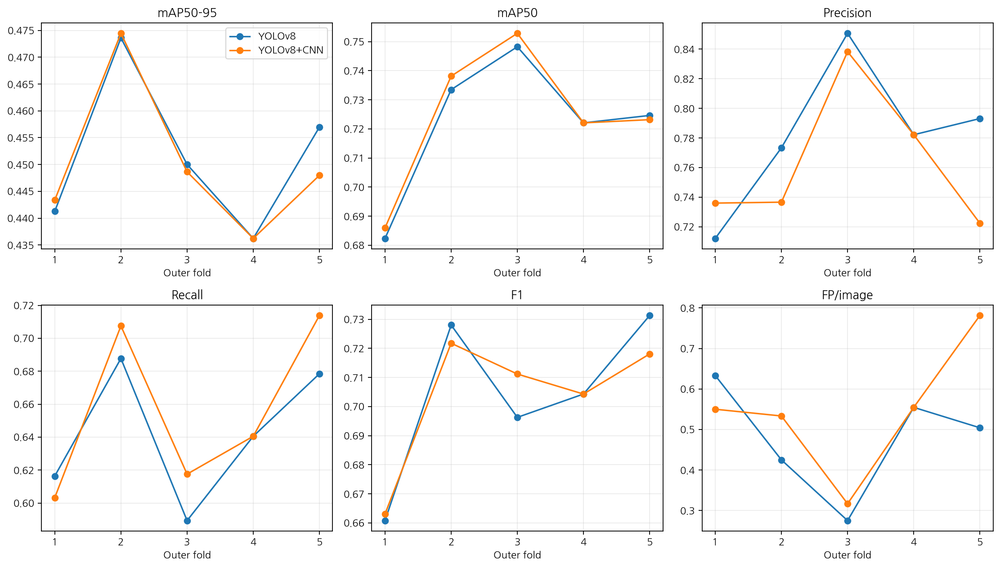

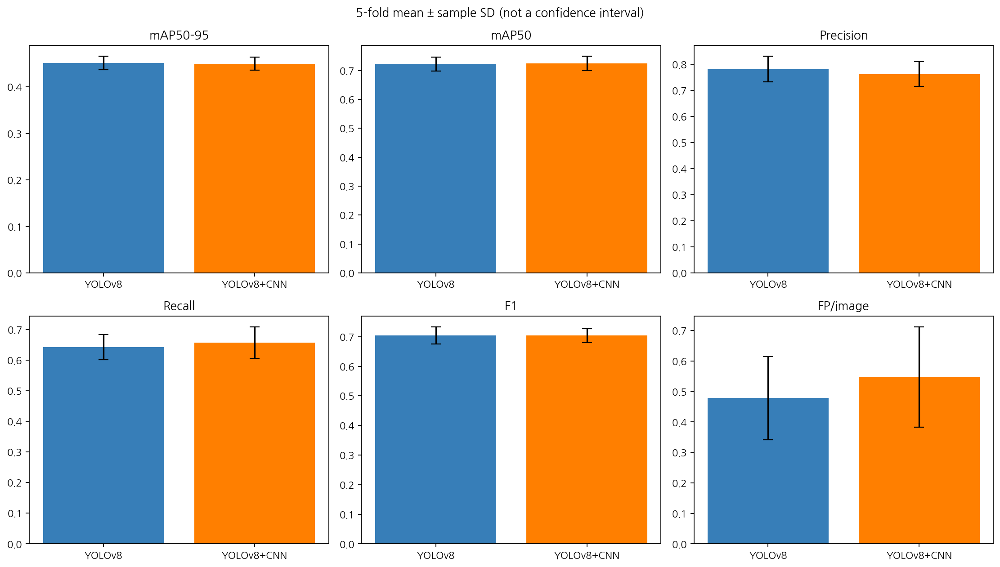

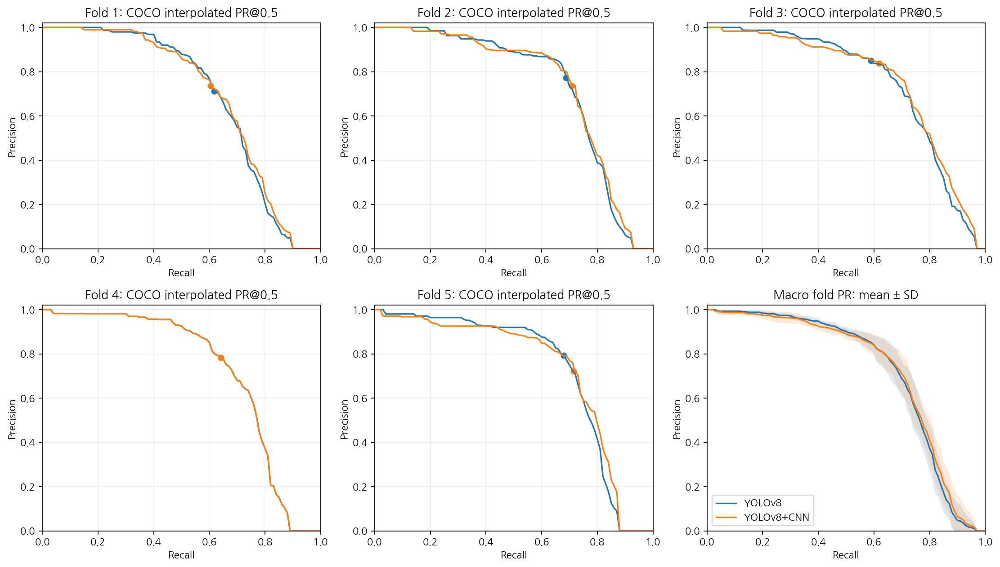

In [4]:
from IPython.display import display, Image as DisplayImage
CTX=report.load_report(RUN_ROOT,EVAL_DIR,DATA_ROOT)
RESULTS,SUMMARY=report.make_tables_graphs(CTX)
print('결과 폴더:', CTX['out'])
display(RESULTS.round(5)); display(SUMMARY.round(5))
for name in ['fold_metrics.png','mean_std.png','pr_curves.png']:
    display(DisplayImage(filename=str(CTX['out']/'graphs'/name),width=1300))


## 5. 성공·실패 5가지 사례와 이유
유형별 후보 이미지 중 고정 seed로 선택합니다. 유형 하나가 없으면 “해당 사례 없음”이라고 출력합니다. 서로 다른 GT의 TP/FP/FN을 IoU 0.5에서 점수순 일대일 매칭합니다. 노란 점선은 분석 대상 후보라서 최종 탐지에서 제외된 박스도 보일 수 있습니다. **CNN은 새 박스를 만들지 않고 YOLO 후보를 재채점합니다.**

라벨 기준 FP에는 라벨 누락 가능성도 있으므로 이미지를 검토하세요. `manual_notes_template.json`의 source 번호를 `MANUAL_NOTES`에 입력한 뒤 이 셀을 다시 실행하면 사람이 작성한 원인 추정도 이미지에 반영됩니다.

,case,title,eligible_images,shown
0,fp_removed,오탐 제거 성공,24,3
1,tp_lost,정답 누락 발생,13,3
2,tp_gained,누락 포트홀 복구,32,3
3,fp_added,새 오탐 발생,62,3
4,both_miss,두 방법의 공통 실패,264,3


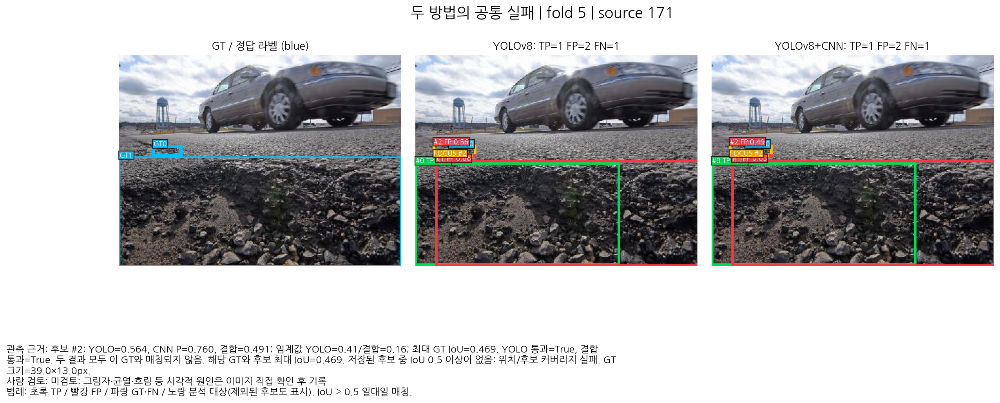

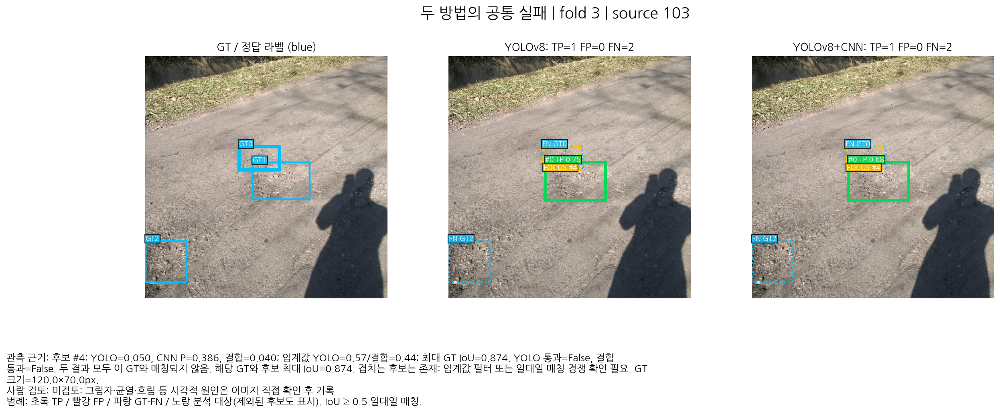

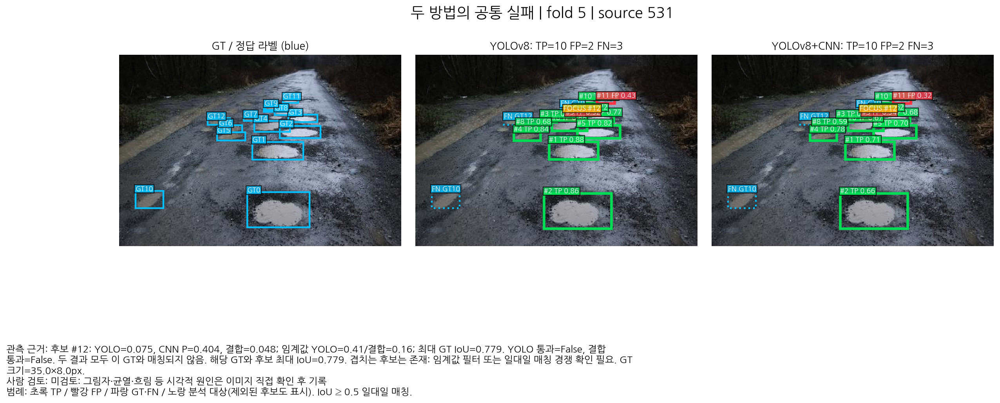

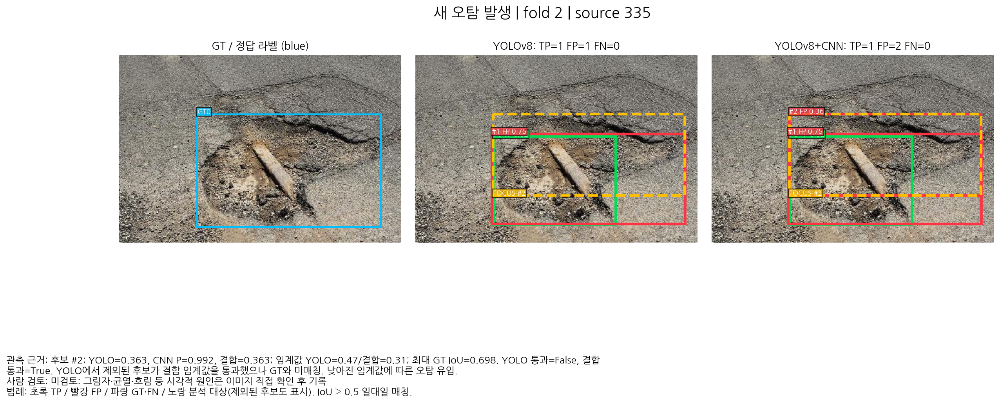

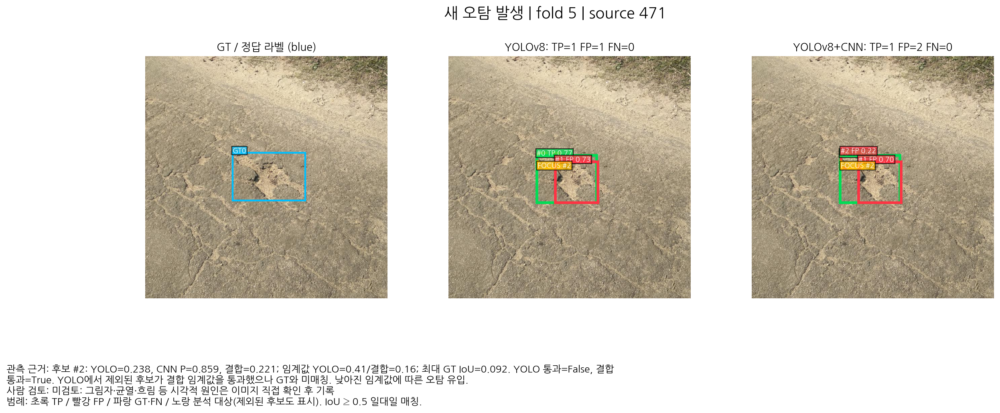

...

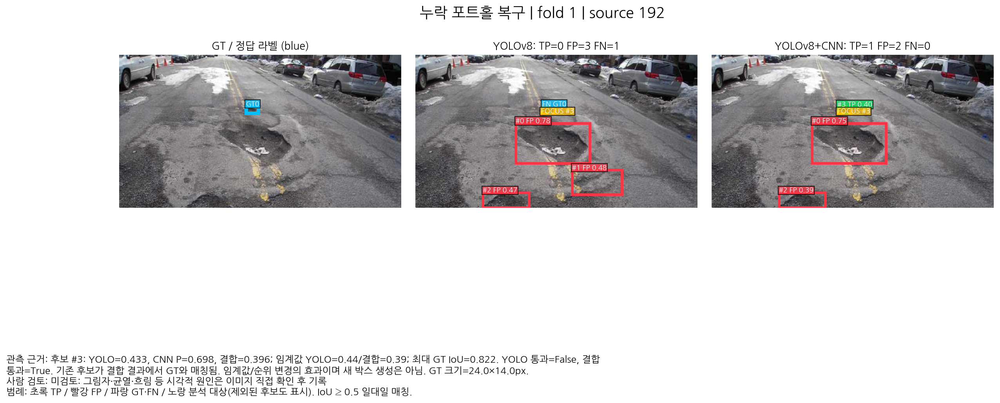

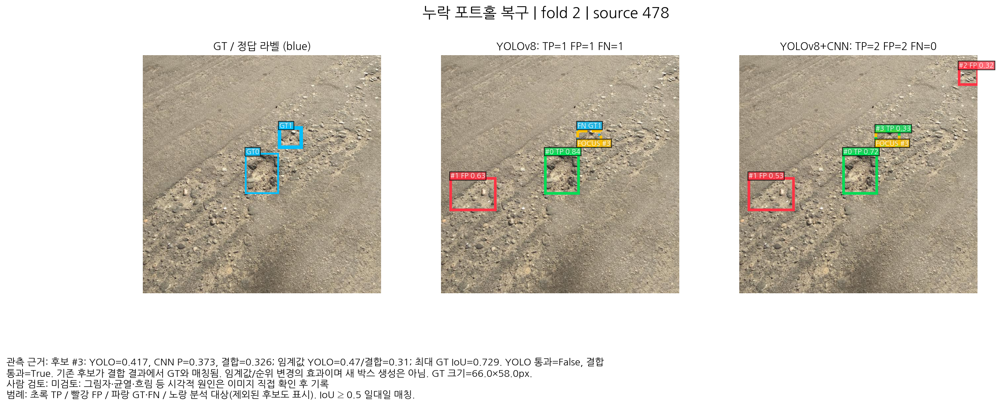

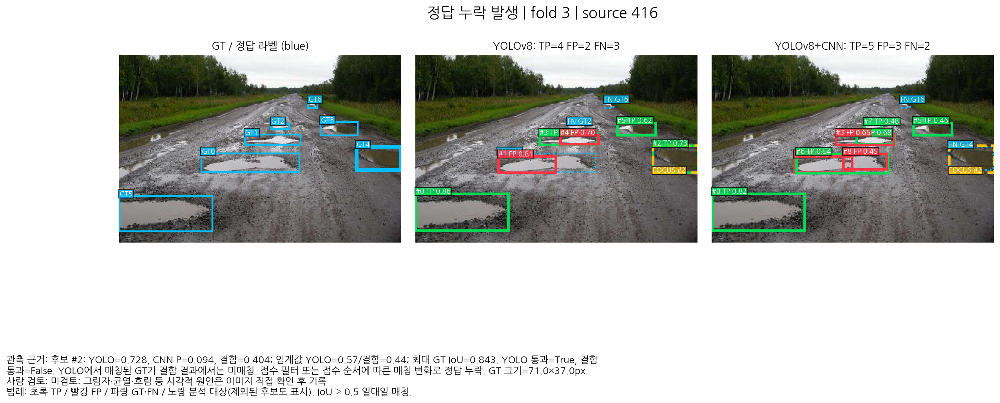

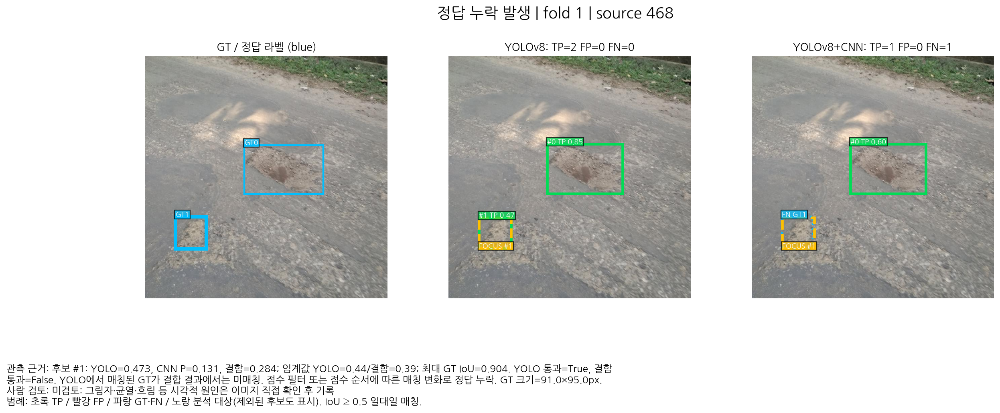

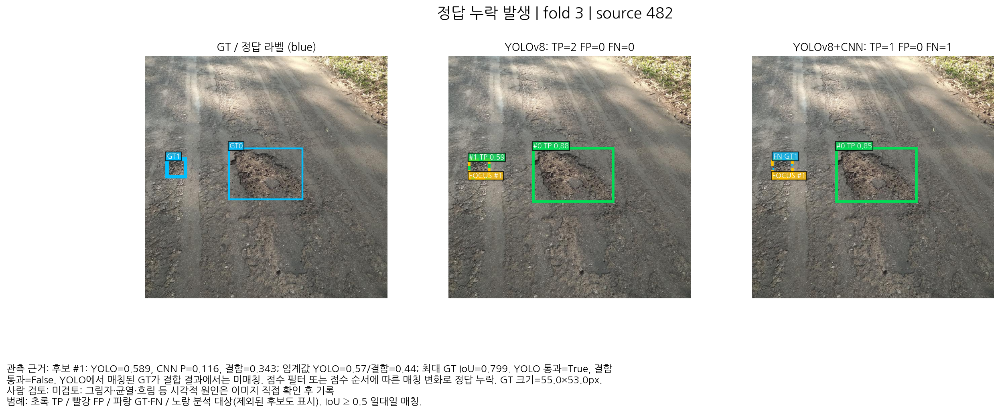

전체 사례의 수치 근거: /content/drive/MyDrive/Pothole/week5_kfold_results/kfold5/evaluation_repaired_20261008_125921_547498/week5_report_20261008_141023/case_selection.csv


In [5]:
CASE_STATUS=report.make_cases(CTX,per_case=CASES_PER_TYPE,seed=SEED,manual_notes=MANUAL_NOTES)
display(CASE_STATUS)
for p in sorted((CTX['out']/'cases').glob('*.png')):
    display(DisplayImage(filename=str(p),width=1500))
print('전체 사례의 수치 근거:', CTX['out']/'case_selection.csv')


## 6. 논문 참고표와 속도 측정 조건

[Wang et al., YOLOv10: Real-Time End-to-End Object Detection (2024), Table 1, §4.1](https://arxiv.org/html/2405.14458v1)은 NVIDIA T4 + TensorRT FP16 조건과 후처리 포함 latency / forward-only latency를 구분합니다. 아래 참고표는 논문 보고값이며, 이 프로젝트의 측정 결과가 아닙니다. 장비·백엔드·데이터·타이머 범위가 달라 단순 속도 우열 비교는 하지 않습니다.

본 노트북의 세 조건은 그 측정 구분과 FP16 설정을 참고한 **자체 PyTorch 실험**입니다. 640은 [Ultralytics predict 공식 기본값](https://docs.ultralytics.com/modes/predict)을 참고했습니다. 논문 재현 실험이나 TensorRT 측정은 아닙니다.

| 조건 | YOLO 입력 설정 | YOLO/CNN 정밀도 | 목적 |
|---|---|---|---|
| A | 저장된 imgsz (현재 실험 800 예상) | FP32 / FP32 | 기존 구성의 속도 기준 |
| B | imgsz=640 | FP32 / FP32 | 해상도 축소 효과 |
| C | imgsz=640 | FP16 / FP16 | GPU에서 정밀도 축소 효과 |

공통: batch=1, `rect=True`이므로 실제 입력은 종횡비·stride에 따라 정사각형보다 작을 수 있음. 동일 fold 가중치·동일 무작위 이미지·동일 conf/NMS/max_det. 양쪽 실행 순서 교대, 워밍업, CUDA synchronize. RAM 이미지의 전처리→YOLO→NMS→CPU 결과→crop/CNN→최종 점수/필터 전체를 측정합니다. 파일 읽기·디코딩·그림 출력은 제외합니다. [PyTorch CUDA 시간 측정 안내](https://docs.pytorch.org/docs/2.14/notes/cuda.html#asynchronous-execution).

- alpha=0인 fold도 CNN을 실행해 **구조 추가 비용**을 측정합니다. CNN 생략 배포 최적화는 이 결과와 구분하세요.
- 기존 inner-val alpha/threshold를 고정해 세 조건을 평가합니다. 640/FP16의 정확도는 별도 sensitivity 결과이며 원래 5-fold 표를 대체하지 않습니다.
- CUDA가 없으면 C는 명시적으로 SKIPPED. 실패 조건은 원인과 traceback을 저장하고 다음 조건으로 진행합니다. 최종 status에서 **15개 조건(fold 5 × case 3)이 모두 OK인지** 확인하세요.


## 7. 모든 fold의 세 조건 속도·정확도 재측정
재학습은 하지 않습니다. GPU와 이미지 읽기 속도에 따라 수 분 이상 걸릴 수 있습니다. 먼저 위의 표·이미지는 이미 저장되어 있습니다. 속도는 fold/조건별 CSV를 중간 저장합니다. 환경 불일치로 중단되면 복구 환경을 복원하거나 `ALLOW_VERSION_DRIFT=True`로 별도 환경 측정임을 명시하세요.

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
속도 Fold1/5 A_original_FP32: imgsz=800, FP32, batch=1, 표본=30
  A_original_FP32 outer 정확도: 30/120
  A_original_FP32 outer 정확도: 60/120
  A_original_FP32 outer 정확도: 90/120
  A_original_FP32 outer 정확도: 120/120
속도 Fold1/5 B_640_FP32: imgsz=640, FP32, batch=1, 표본=30
  B_640_FP32 outer 정확도: 30/120
  B_640_FP32 outer 정확도: 60/120
  B_640_FP32 outer 정확도: 90/120
  B_640_FP32 outer 정확도: 120/120
속도 Fold1/5 C_640_FP16: imgsz=640, FP16, batch=1, 표본=30
  C_640_FP16 outer 정확도: 30/120
  C_640_FP16 outer 정확도: 60/120
  C_640_FP16 outer 정확도: 90/120
  C_640_FP16 outer 정확도: 120/120
속도 Fold2/5 A_original_FP32: imgsz=800, FP32, batch=1, 표본=30
  A_original_FP32 outer 정확도: 30/120
  A_original_FP32 outer 정확도: 60/120
  A_origin

,fold,case,status,reason
0,1,A_original_FP32,OK,
1,1,B_640_FP32,OK,
2,1,C_640_FP16,OK,
3,2,A_original_FP32,OK,
4,2,B_640_FP32,OK,
5,2,C_640_FP16,OK,
6,3,A_original_FP32,OK,
7,3,B_640_FP32,OK,
8,3,C_640_FP16,OK,
9,4,A_original_FP32,OK,


각 fold/조건별 평균·중앙값·P95(ms)·FPS


,fold,case,model,imgsz,precision,mean_ms,median_ms,p95_ms,fps,samples,unique_images,mean_candidates
0,1,A_original_FP32,YOLOv8,800,FP32,7.302,7.241,7.537,136.954,90,30,45.067
1,1,A_original_FP32,YOLOv8+CNN,800,FP32,10.051,9.326,13.768,99.495,90,30,45.067
2,1,B_640_FP32,YOLOv8,640,FP32,5.990,5.535,6.570,166.954,90,30,38.200
3,1,B_640_FP32,YOLOv8+CNN,640,FP32,8.156,7.492,10.741,122.616,90,30,38.200
4,1,C_640_FP16,YOLOv8,640,FP16,4.185,3.298,3.607,238.924,90,30,38.067
5,1,C_640_FP16,YOLOv8+CNN,640,FP16,7.499,5.704,9.709,133.355,90,30,38.067
6,2,A_original_FP32,YOLOv8,800,FP32,7.053,7.297,7.568,141.784,90,30,40.000
7,2,A_original_FP32,YOLOv8+CNN,800,FP32,9.120,8.683,11.369,109.654,90,30,40.000
8,2,B_640_FP32,YOLOv8,640,FP32,5.859,5.679,6.628,170.670,90,30,36.300
9,2,B_640_FP32,YOLOv8+CNN,640,FP32,7.780,7.531,9.681,128.531,90,30,36.300


mean_ms        median_ms         p95_ms         \
                              mean    std      mean    std    mean    std   
case            model                                                       
A_original_FP32 YOLOv8       7.205  0.093     7.327  0.059   7.615  0.062   
                YOLOv8+CNN   9.463  0.415     9.229  0.359  11.783  1.137   
B_640_FP32      YOLOv8       5.963  0.087     5.883  0.348   6.647  0.052   
                YOLOv8+CNN   7.933  0.232     7.705  0.260   9.760  0.695   
C_640_FP16      YOLOv8       3.504  0.391     3.312  0.041   3.678  0.230   
                YOLOv8+CNN   5.875  0.936     5.423  0.352   7.659  1.233   

                                fps         mean_candidates         
                               mean     std            mean    std  
case            model                                               
A_original_FP32 YOLOv8      138.809   1.816          41.987  5.565  
                YOLOv8+CNN  105.832   4.603          41.987  5.565  
B_640_FP32      YOLOv8      167.718   2.437          36.780  4.412  
                YOLOv8+CNN  126.145   3.736          36.780  4.412  
C_640_FP16      YOLOv8      287.965  28.462          36.687  4.327  
                YOLOv8+CNN  173.210  23.635          36.687  4.327

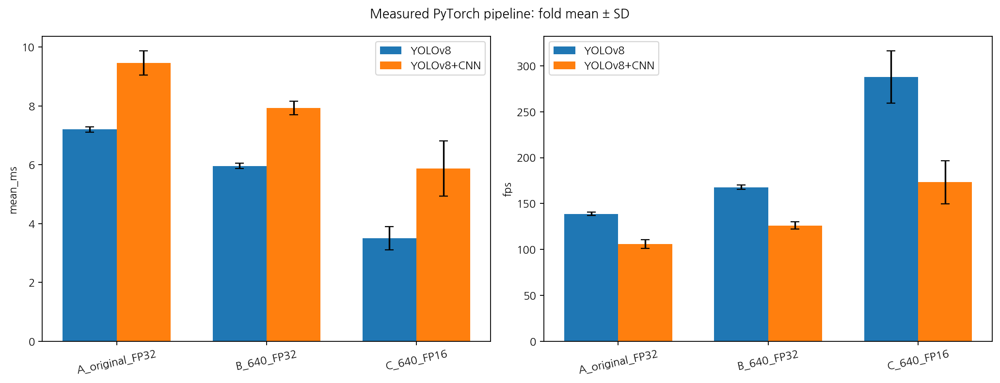

설정 변경에 따른 정확도 — 기존 inner-val alpha/threshold 고정


,fold,case,model,threshold,alpha,map,map_50,map_75,map_small,map_medium,map_large,tp,fp,fn,precision,recall,f1,fp_per_image
0,1,A_original_FP32,YOLOv8,0.44,0.00,0.44106,0.68234,0.50398,0.19319,0.39811,0.57333,188,76,117,0.71212,0.61639,0.66081,0.63333
1,1,A_original_FP32,YOLOv8+CNN,0.39,0.25,0.44318,0.68580,0.50514,0.19305,0.39338,0.57954,184,66,121,0.73600,0.60328,0.66306,0.55000
2,1,B_640_FP32,YOLOv8,0.44,0.00,0.44603,0.70842,0.50127,0.17048,0.41167,0.57784,199,59,106,0.77132,0.65246,0.70693,0.49167
3,1,B_640_FP32,YOLOv8+CNN,0.39,0.25,0.45556,0.71681,0.51482,0.17016,0.40803,0.59494,190,47,115,0.80169,0.62295,0.70111,0.39167
4,1,C_640_FP16,YOLOv8,0.44,0.00,0.44627,0.70858,0.50160,0.16921,0.41178,0.57793,199,58,106,0.77432,0.65246,0.70819,0.48333
5,1,C_640_FP16,YOLOv8+CNN,0.39,0.25,0.45532,0.71670,0.51396,0.16778,0.40792,0.59509,190,46,115,0.80508,0.62295,0.70240,0.38333
6,2,A_original_FP32,YOLOv8,0.47,0.00,0.47358,0.73352,0.52123,0.32121,0.39257,0.59435,174,51,79,0.77333,0.68775,0.72803,0.42500
7,2,A_original_FP32,YOLOv8+CNN,0.31,0.25,0.47440,0.73815,0.51945,0.33183,0.39033,0.59318,179,64,74,0.73663,0.70751,0.72177,0.53333
8,2,B_640_FP32,YOLOv8,0.47,0.00,0.47989,0.75371,0.55335,0.30587,0.40260,0.59760,178,54,75,0.76724,0.70356,0.73402,0.45000
9,2,B_640_FP32,YOLOv8+CNN,0.31,0.25,0.48018,0.75683,0.54847,0.31574,0.39868,0.59632,181,65,72,0.73577,0.71542,0.72545,0.54167


map            map_50          precision  \
                               mean      std     mean      std      mean   
case            model                                                      
A_original_FP32 YOLOv8      0.45151  0.01475  0.72216  0.02450   0.78228   
                YOLOv8+CNN  0.44990  0.01456  0.72423  0.02497   0.76310   
B_640_FP32      YOLOv8      0.45895  0.01718  0.73392  0.02220   0.80104   
                YOLOv8+CNN  0.46029  0.01626  0.73801  0.02228   0.78777   
C_640_FP16      YOLOv8      0.45905  0.01718  0.73425  0.02236   0.80218   
                YOLOv8+CNN  0.46017  0.01615  0.73823  0.02239   0.78924   

                                      recall                f1           
                                std     mean      std     mean      std  
case            model                                                    
A_original_FP32 YOLOv8      0.04949  0.64250  0.04139  0.70415  0.02850  
                YOLOv8+CNN  0.04773  0.65655  0.05123  0.70369  0.02367  
B_640_FP32      YOLOv8      0.03663  0.65273  0.03364  0.71817  0.01373  
                YOLOv8+CNN  0.05090  0.65801  0.04964  0.71442  0.01175  
C_640_FP16      YOLOv8      0.03503  0.65210  0.03455  0.71826  0.01411  
                YOLOv8+CNN  0.04984  0.65679  0.04967  0.71433  0.01156

In [7]:
SPEED,SCENARIO_ACCURACY,SPEED_STATUS=report.benchmark_all(
    CTX,images_per_fold=BENCH_IMAGES_PER_FOLD,repeats=BENCH_REPEATS,
    warmup=BENCH_WARMUP,seed=SEED,full_accuracy=FULL_SCENARIO_ACCURACY,
    allow_version_drift=ALLOW_VERSION_DRIFT,
)
print('조건별 실행 상태'); display(SPEED_STATUS)
print('각 fold/조건별 평균·중앙값·P95(ms)·FPS'); display(SPEED.round(3))
if not SPEED.empty:
    display(SPEED.groupby(['case','model'])[['mean_ms','median_ms','p95_ms','fps','mean_candidates']].agg(['mean','std']).round(3))
    display(DisplayImage(filename=str(CTX['out']/'speed/speed_comparison.png'),width=1300))
if not SCENARIO_ACCURACY.empty:
    print('설정 변경에 따른 정확도 — 기존 inner-val alpha/threshold 고정')
    display(SCENARIO_ACCURACY.round(5))
    display(SCENARIO_ACCURACY.groupby(['case','model'])[['map','map_50','precision','recall','f1']].agg(['mean','std']).round(5))
if len(SPEED_STATUS)!=15 or not (SPEED_STATUS.status=='OK').all():
    print('일부 조건이 완료되지 않았습니다. speed/status.csv와 error.txt를 확인하세요.')


## 8. 보고서·CSV·그림 한 번에 저장
HTML은 ZIP을 풀고 `index.html`을 열면 그림과 표를 함께 볼 수 있습니다. 값은 0~1 비율이고, 100을 곱하면 %입니다. 변화량을 백분율로 표시할 때는 %p를 사용하세요. 반복 이미지의 latency 샘플은 독립 데이터셋 표본이 아닙니다.

In [8]:
import shutil
INDEX=report.make_index(CTX)
# 재현을 위해 실행한 분석 코드와 라이선스도 결과 폴더에 보관
code_out=CTX['out']/'analysis_code'; code_out.mkdir(exist_ok=True)
for name in ['week5_report.py','week5_coco_fixed.py','week5_recovery.py','OFL.txt']:
    shutil.copy2(BUNDLE/name,code_out/name)
ZIP=shutil.make_archive(str(CTX['out']),'zip',root_dir=CTX['out'])
print('HTML:', INDEX)
print('전체 결과 ZIP:', ZIP)
print('원래 평가 결과:', EVAL_DIR)
# 자동 다운로드를 원하면 아래 두 줄의 주석을 해제하세요.
# from google.colab import files
# files.download(ZIP)


HTML: /content/drive/MyDrive/Pothole/week5_kfold_results/kfold5/evaluation_repaired_20261008_125921_547498/week5_report_20261008_141023/index.html
전체 결과 ZIP: /content/drive/MyDrive/Pothole/week5_kfold_results/kfold5/evaluation_repaired_20261008_125921_547498/week5_report_20261008_141023.zip
원래 평가 결과: /content/drive/MyDrive/Pothole/week5_kfold_results/kfold5/evaluation_repaired_20261008_125921_547498


## 검증 범위
이 노트북은 합성 5-fold 데이터에서 COCO AP 재계산·CSV 일치 검증·5개 사례 분류·중복/빈 박스 매칭·PR 그래프·이미지 생성을 테스트했습니다. 실제 Drive 이미지와 가중치는 여기서 제공되지 않았으므로 GPU 추론과 실측 수치는 사용자의 Colab 실행으로 확인해야 합니다. 새 속도 수치는 미리 채워 넣지 않았습니다.

Nanum Gothic 한글 폰트는 SIL Open Font License 1.1에 따라 포함했으며 라이선스는 코드 번들의 OFL.txt에 보관합니다.
